# AlUla Survival Simulation

## Project Overview

Can we predict whether a player will survive a simulated AlUla desert scenario using only the information available before the scenario begins? We use the player’s starting condition, available water and shelter, expected exposure time, temperature, and creature characteristics to predict one of two outcomes: survives or does not survive. This is a binary classification problem, and we evaluate how well the model predicts survival in scenarios with weather records it has never seen during training.

## Dataset Information

* **Number of Scenarios (rows):** 12,660
* **Number of Columns:** 58
* **Biomes:** Coastal, Mountain, Desert, Oasis
* **Creatures:** 47 Saudi/Arabian creatures, mapped from 211 original creatures
* **Skills:** 262 skills used by 3 characters (Kliff, Damiane, Oongka)
* **Target Variable:** `player_survived_simulated` (1 = survived, 0 = did not survive)

> The survival label is simulated so every finding describes the simulation and not real-world survival.


# Dataset Description

The dataset is a single table (`alula_survival_weather_skills_combined.csv`) that joins three source files:

* `player_survival_ml_ready.csv`: the simulated scenarios (player, environment, creature, and the survival label).
* `cleaned_weather.csv`: a weather table cleaned from the previous mini project done.
* `crimson_desert_skills_alula_enriched.csv`: a skill tree of the game crimson desert that was linked with alula desert scenarios.

The columns are grouped below.

### Scenario and Environment

* `scenario_id`: String variable, Unique identifier of the scenario.
* `biome`: Categorical variable, Biome of the scenario (coastal, mountain, desert, oasis).
* `temperature_c`: Float variable, Scenario temperature in °C.
* `humidity_pct`: Float variable, Scenario humidity in %.
* `wind_speed_kmh`: Float variable, Scenario wind speed in km/h.
* `exposure_hours`: Integer variable, Hours the player is exposed to the environment (1–72).
* `scenario_context`: Categorical variable, Context of the scenario (encounter, travel, general).

### Player

* `player_health_pct`, `player_stamina_pct`, `player_hydration_pct`, `player_hunger_pct`: Integer variables, Player status in %.
* `player_combat_skill_1_to_5`: Integer variable, Combat skill level (1–5).
* `player_heat_protection_0_to_5`, `player_cold_protection_0_to_5`: Integer variables, Protection level against heat / cold (0–5).
* `shelter_available`: Binary variable (0/1), Whether a shelter is available.
* `water_available_liters`: Float variable, Water available to the player in liters.

### Creature

* `ark_creature_original`: String variable, Original creature name.
* `saudi_creature_en`: String variable, Saudi/Arabian creature the original creature is mapped to.
* `creature_encounter_happened`: Binary variable (0/1), Whether the creature encounter happened.
* `creature_threat_1_to_5`, `creature_heat_tolerance_1_to_5`, `creature_cold_tolerance_1_to_5`, `creature_drought_tolerance_1_to_5`, `creature_endurance_1_to_5`, `creature_mobility_1_to_5`, `creature_defense_1_to_5`: Integer variables, Creature traits (1–5).
* `creature_habitat_mismatch`: Binary variable (0/1), Whether the creature is outside its natural habitat.

### Weather (matched to each scenario)

* `weather_row_id`: Integer variable, Identifier of the matched weather record.
* `weather_temperature_c`, `weather_humidity_pct`, `weather_wind_speed_kmh`, `weather_precipitation_pct`, `weather_atmospheric_pressure_hpa`, `weather_visibility_km`, `weather_uv_index`: Numeric variables, Measurements of the matched weather record.
* `weather_cloud_cover_code`, `weather_season_code`, `weather_location_code`, `weather_type_code`: Integer variables, Encoded weather categories (cloud cover, season, location type, weather type). The file has no legend, so they are decoded in section 4.9.
* `weather_climate_match_distance`: Float variable, How far the matched weather is from the scenario (0 = closest).

### Equipped Skill

* `equipped_skill_id`, `equipped_skill_character`, `equipped_skill_name`, `equipped_skill_role`: Skill identifier, owner character, name and role.
* `equipped_skill_description`, `equipped_skill_alula_application`, `equipped_skill_alula_scenario`: Text variables, Description of the skill and how it applies in AlUla.
* `equipped_skill_alula_survival_score`, `equipped_skill_alula_traversal_score`, `equipped_skill_alula_combat_score`, `equipped_skill_alula_exploration_score`: Integer variables, Skill scores (1–5).
* `equipped_skill_alula_weighted_score`: Float variable, Weighted combination of the four scores.
* `equipped_skill_alula_priority`: Categorical variable, Skill priority (Low, Medium, High).
* `equipped_skill_source_url`: String variable, Source of the skill information.

### Target and Provenance

* `player_survived_simulated`: Binary variable (0/1), Simulated survival outcome (**target**).
* `weather_match_method`, `skill_assignment_method`, `survival_label_origin`: String variables, How the weather, the skill and the label were produced.

# 1.Import Libraries

* import the essential Python libraries used for data loading, analysis, and visualization.

In [ ]:
# Data Manipulation
import numpy as np
import pandas as pd
# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_palette("viridis")
pd.set_option("display.max_columns", None)   # the dataset has 58 columns

#Model imports
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_predict, cross_val_score, learning_curve, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score


# 2.Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = "alula_survival_weather_skills_combined.csv"
df = pd.read_csv(file_path)

# 3.Data Understanding

* An initial exploration of the dataset to understand its structure, size, and features.

In [ ]:
# Display the first 5 rows
df.head()

,ark_creature_original,saudi_creature_en,biome,temperature_c,humidity_pct,wind_speed_kmh,exposure_hours,player_health_pct,player_stamina_pct,player_hydration_pct,player_hunger_pct,player_combat_skill_1_to_5,player_heat_protection_0_to_5,player_cold_protection_0_to_5,shelter_available,water_available_liters,creature_encounter_happened,creature_threat_1_to_5,creature_heat_tolerance_1_to_5,creature_cold_tolerance_1_to_5,creature_drought_tolerance_1_to_5,creature_endurance_1_to_5,creature_mobility_1_to_5,creature_defense_1_to_5,creature_habitat_mismatch,player_survived_simulated,scenario_id,weather_row_id,weather_temperature_c,weather_humidity_pct,weather_wind_speed_kmh,weather_precipitation_pct,weather_cloud_cover_code,weather_atmospheric_pressure_hpa,weather_uv_index,weather_season_code,weather_visibility_km,weather_location_code,weather_type_code,weather_climate_match_distance,equipped_skill_id,equipped_skill_character,equipped_skill_name,equipped_skill_role,equipped_skill_description,equipped_skill_alula_application,equipped_skill_alula_scenario,equipped_skill_alula_survival_score,equipped_skill_alula_traversal_score,equipped_skill_alula_combat_score,equipped_skill_alula_exploration_score,equipped_skill_alula_weighted_score,equipped_skill_alula_priority,equipped_skill_source_url,scenario_context,weather_match_method,skill_assignment_method,survival_label_origin
0,Achatina,Red Sea sea snail,coastal,27.8,80.4,8.7,64,92,24,36,60,3,1,3,0,4.8,1,1,3,2,1,2,2,2,0,1,ALULA-SIM-00001,11656,28.0,81,8.0,67.0,2,1009.52,3,0,3.5,2,1,0.0702,CD-SK-247,Oongka,Frost Mantle,Defense,Frost Mantle (Oongka): Creates a barrier of ic...,Protect the character while fighting at a rock...,Holding a narrow canyon chokepoint,5,1,4,2,3.3,Medium,https://crimsondb.gg/skill-tree/oongka,encounter,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified
1,Achatina,Red Sea sea snail,coastal,34.4,58.8,29.4,53,84,12,18,84,3,1,3,0,0.3,0,1,3,2,1,2,2,2,0,0,ALULA-SIM-00002,2138,31.0,70,29.0,96.0,3,1014.53,1,0,6.5,1,0,0.7038,CD-SK-051,Kliff,Healing Force Palm,Support,Healing Force Palm changes a charged Force Pal...,Use this to support recovery after difficult e...,Recovering between desert encounters,5,3,3,4,3.9,High,https://www.pywel.app/en/database/skills/,travel,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified
2,Achatina,Red Sea sea snail,coastal,23.7,76.2,29.7,17,24,53,81,57,3,1,2,1,4.5,0,1,3,2,1,2,2,2,0,1,ALULA-SIM-00003,7709,24.0,75,27.5,73.0,3,1018.54,13,3,3.5,2,0,0.1965,CD-SK-117,Damiane,Skystep,Mobility,Skystep (Damiane): The effect described for th...,Use the extra vertical movement to navigate st...,Ascending rocky terraces,5,5,2,5,4.4,High,https://www.pywel.app/en/database/skills/,general,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified
3,Achatina,Red Sea sea snail,coastal,29.6,89.6,1.5,62,33,45,88,18,5,0,3,1,0.6,0,1,3,2,1,2,2,2,0,0,ALULA-SIM-00004,840,31.0,92,4.0,99.0,3,1010.90,14,0,4.5,0,3,0.2974,CD-SK-114,Damiane,Health,Resource,Health (Damiane): Increases the character’s ab...,Use this to support recovery after difficult e...,Recovering between desert encounters,5,3,3,4,3.9,High,https://www.pywel.app/en/database/skills/,travel,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified
4,Achatina,Red Sea sea snail,coastal,38.8,53.7,26.5,68,72,55,23,58,1,3,1,0,1.2,0,1,3,2,1,2,2,2,0,1,ALULA-SIM-00005,4060,39.0,70,27.0,90.0,3,1011.48,10,2,1.5,1,1,0.8164,CD-SK-256,Oongka,Swift Flight,Mobility,Swift Flight (Oongka): The effect described fo...,Use the travel ability to move between cliffs ...,Gliding over AlUla valleys,5,5,2,5,4.4,High,https://crimsondb.gg/skill-tree/oongka,travel,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified


In [ ]:
# Display the last 5 rows
# This helps us check if there are any unusual values or issues at the end of the file.
df.tail()

,ark_creature_original,saudi_creature_en,biome,temperature_c,humidity_pct,wind_speed_kmh,exposure_hours,player_health_pct,player_stamina_pct,player_hydration_pct,player_hunger_pct,player_combat_skill_1_to_5,player_heat_protection_0_to_5,player_cold_protection_0_to_5,shelter_available,water_available_liters,creature_encounter_happened,creature_threat_1_to_5,creature_heat_tolerance_1_to_5,creature_cold_tolerance_1_to_5,creature_drought_tolerance_1_to_5,creature_endurance_1_to_5,creature_mobility_1_to_5,creature_defense_1_to_5,creature_habitat_mismatch,player_survived_simulated,scenario_id,weather_row_id,weather_temperature_c,weather_humidity_pct,weather_wind_speed_kmh,weather_precipitation_pct,weather_cloud_cover_code,weather_atmospheric_pressure_hpa,weather_uv_index,weather_season_code,weather_visibility_km,weather_location_code,weather_type_code,weather_climate_match_distance,equipped_skill_id,equipped_skill_character,equipped_skill_name,equipped_skill_role,equipped_skill_description,equipped_skill_alula_application,equipped_skill_alula_scenario,equipped_skill_alula_survival_score,equipped_skill_alula_traversal_score,equipped_skill_alula_combat_score,equipped_skill_alula_exploration_score,equipped_skill_alula_weighted_score,equipped_skill_alula_priority,equipped_skill_source_url,scenario_context,weather_match_method,skill_assignment_method,survival_label_origin
12655,Yutyrannus,Arabian wolf,desert,15.1,41.1,27.5,4,89,66,79,54,2,3,4,0,0.8,1,4,4,4,3,4,4,4,0,0,ALULA-SIM-12656,2645,17.0,37,15.0,60.0,2,1033.20,1,3,8.0,0,2,1.0879,CD-SK-010,Kliff,Shield Bash,Defense,Shield Bash (Kliff): It strikes while blocking...,Use a shield or repelling technique to maintai...,Pushing through a canyon blockade,4,1,4,1,2.8,Medium,https://www.pywel.app/en/database/skills/,encounter,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified
12656,Yutyrannus,Arabian wolf,desert,20.3,21.1,15.2,71,76,68,44,21,1,3,4,1,0.4,0,4,4,4,3,4,4,4,0,0,ALULA-SIM-12657,7720,21.0,23,15.0,91.0,3,938.26,3,2,12.0,2,0,0.1302,CD-SK-260,Oongka,Spirit,Resource,Spirit (Oongka): Expands the resource capacity...,Useful when several encounters occur before re...,Extended desert encounters,4,2,4,2,3.2,Medium,https://crimsondb.gg/skill-tree/oongka,travel,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified
12657,Yutyrannus,Arabian wolf,mountain,4.3,30.2,24.7,40,36,45,85,24,3,1,1,0,0.7,1,4,4,4,3,4,4,4,0,0,ALULA-SIM-12658,6515,5.0,21,14.5,17.0,1,886.60,13,0,0.5,0,0,0.9704,CD-SK-173,Damiane,Nature's Snare,Defense,Nature's Snare (Damiane): Generates a wind bar...,Use the wind-based defense when hostile projec...,Surviving ranged canyon ambushes,5,1,4,3,3.4,Medium,https://www.pywel.app/en/database/skills/,encounter,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified
12658,Yutyrannus,Arabian wolf,desert,21.5,14.5,40.8,66,42,24,65,71,3,1,4,0,0.7,1,4,4,4,3,4,4,4,0,0,ALULA-SIM-12659,7720,21.0,23,15.0,91.0,3,938.26,3,2,12.0,2,0,2.1925,CD-SK-222,Oongka,Devastation,Offense,Devastation (Oongka): The effect described for...,Use the forceful attack to handle enemies gath...,Breaking a desert ambush,3,1,5,2,2.7,Medium,https://crimsondb.gg/skill-tree/oongka,encounter,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified
12659,Yutyrannus,Arabian wolf,coastal,31.2,45.5,18.5,53,84,65,85,55,2,2,0,0,4.0,1,4,4,4,3,4,4,4,1,1,ALULA-SIM-12660,2559,30.0,50,14.5,41.0,2,1003.80,4,3,5.5,0,0,0.4292,CD-SK-073,Kliff,Nature's Veil,Defense,Nature's Veil (Kliff): It holds protective win...,Use the wind-based defense when hostile projec...,Surviving ranged canyon ambushes,5,1,4,3,3.4,Medium,https://www.pywel.app/en/database/skills/,encounter,nearest_temperature_humidity_wind,seeded_context_role_sampling,preexisting_simulated_label_unmodified


In [ ]:
# Display column names as a list
print("Columns:", df.columns.tolist())

Columns: ['ark_creature_original', 'saudi_creature_en', 'biome', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'exposure_hours', 'player_health_pct', 'player_stamina_pct', 'player_hydration_pct', 'player_hunger_pct', 'player_combat_skill_1_to_5', 'player_heat_protection_0_to_5', 'player_cold_protection_0_to_5', 'shelter_available', 'water_available_liters', 'creature_encounter_happened', 'creature_threat_1_to_5', 'creature_heat_tolerance_1_to_5', 'creature_cold_tolerance_1_to_5', 'creature_drought_tolerance_1_to_5', 'creature_endurance_1_to_5', 'creature_mobility_1_to_5', 'creature_defense_1_to_5', 'creature_habitat_mismatch', 'player_survived_simulated', 'scenario_id', 'weather_row_id', 'weather_temperature_c', 'weather_humidity_pct', 'weather_wind_speed_kmh', 'weather_precipitation_pct', 'weather_cloud_cover_code', 'weather_atmospheric_pressure_hpa', 'weather_uv_index', 'weather_season_code', 'weather_visibility_km', 'weather_location_code', 'weather_type_code', 'weather_climate

In [ ]:
# Check the shape of the dataset (rows, columns)
print("Dataset Shape:", df.shape)

Dataset Shape: (12660, 58)


In [ ]:
# Display information about the dataset
# Check the number of entries, column names, data types, and non-null values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12660 entries, 0 to 12659
Data columns (total 58 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   ark_creature_original                   12660 non-null  object 
 1   saudi_creature_en                       12660 non-null  object 
 2   biome                                   12660 non-null  object 
 3   temperature_c                           12660 non-null  float64
 4   humidity_pct                            12660 non-null  float64
 5   wind_speed_kmh                          12660 non-null  float64
 6   exposure_hours                          12660 non-null  int64  
 7   player_health_pct                       12660 non-null  int64  
 8   player_stamina_pct                      12660 non-null  int64  
 9   player_hydration_pct                    12660 non-null  int64  
 10  player_hunger_pct                       12660 non-null  in

In [ ]:
# Display summary statistics for numerical columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
temperature_c,12660.0,26.569344,10.686374,1.00,19.4000,26.8000,34.800000,47.0000
humidity_pct,12660.0,40.856888,21.094982,8.00,24.2000,37.7000,55.325000,95.0000
wind_speed_kmh,12660.0,18.911856,11.314133,0.00,9.2000,18.5000,28.300000,42.0000
exposure_hours,12660.0,36.461216,20.765537,1.00,19.0000,37.0000,54.000000,72.0000
player_health_pct,12660.0,57.239573,24.843545,15.00,36.0000,57.0000,79.000000,100.0000
player_stamina_pct,12660.0,54.913823,26.235191,10.00,32.0000,55.0000,78.000000,100.0000
player_hydration_pct,12660.0,52.611374,27.814145,5.00,29.0000,53.0000,77.000000,100.0000
player_hunger_pct,12660.0,52.502449,27.874790,5.00,28.0000,52.5000,77.000000,100.0000
player_combat_skill_1_to_5,12660.0,2.995735,1.421450,1.00,2.0000,3.0000,4.000000,5.0000
player_heat_protection_0_to_5,12660.0,2.523618,1.707868,0.00,1.0000,3.0000,4.000000,5.0000


In [ ]:
# Display summary statistics for text / categorical columns
display(df.select_dtypes(exclude="number").describe().T)

,count,unique,top,freq
ark_creature_original,12660,211,Achatina,60
saudi_creature_en,12660,47,Dromedary camel,1020
biome,12660,4,desert,5432
scenario_id,12660,12660,ALULA-SIM-00001,1
equipped_skill_id,12660,262,CD-SK-051,590
equipped_skill_character,12660,3,Kliff,4766
equipped_skill_name,12660,163,Healing Force Palm,590
equipped_skill_role,12660,8,Defense,2937
equipped_skill_description,12660,262,Healing Force Palm changes a charged Force Pal...,590
equipped_skill_alula_application,12660,38,Use this reaction or evasive technique when en...,1416


In [ ]:
# Number of unique values in each column
df.nunique().sort_values()

,0
survival_label_origin,1
weather_match_method,1
skill_assignment_method,1
shelter_available,2
equipped_skill_source_url,2
player_survived_simulated,2
creature_habitat_mismatch,2
creature_encounter_happened,2
scenario_context,3
equipped_skill_alula_priority,3


In [ ]:
# Unique values of the low-cardinality categorical columns
for col in ["biome", "scenario_context", "equipped_skill_character", "equipped_skill_role",
            "equipped_skill_alula_priority", "weather_match_method",
            "skill_assignment_method", "survival_label_origin"]:
    print(col, "->", df[col].unique().tolist())

biome -> ['coastal', 'mountain', 'desert', 'oasis']
scenario_context -> ['encounter', 'travel', 'general']
equipped_skill_character -> ['Oongka', 'Kliff', 'Damiane']
equipped_skill_role -> ['Defense', 'Support', 'Mobility', 'Resource', 'Utility', 'Ranged', 'Control', 'Offense']
equipped_skill_alula_priority -> ['Medium', 'High', 'Low']
weather_match_method -> ['nearest_temperature_humidity_wind']
skill_assignment_method -> ['seeded_context_role_sampling']
survival_label_origin -> ['preexisting_simulated_label_unmodified']


# 4.Data Cleaning and Preprocessing

* check the dataset for missing values, duplicates, wrong data types, impossible values, and inconsistent records, and prepare the columns for analysis.
This step ensures the data is clean, reliable, and ready for deeper exploration and modeling.

## 4.1 Missing Values and Duplicates

In [ ]:
# Check for missing values
print("Total missing values:", df.isnull().sum().sum())
print("Columns with missing values:", df.columns[df.isnull().any()].tolist())

Total missing values: 0
Columns with missing values: []


In [ ]:
# Check for duplicated rows, and for duplicated scenario_id
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated scenario_id:", df["scenario_id"].duplicated().sum())
print("Duplicated rows ignoring scenario_id:", df.drop(columns="scenario_id").duplicated().sum())

Duplicated rows: 0
Duplicated scenario_id: 0
Duplicated rows ignoring scenario_id: 0


In [ ]:
# Check for leading / trailing spaces in text columns
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    n = (df[col] != df[col].str.strip()).sum()
    if n > 0:
        print(col, "->", n, "values with extra spaces")
print("Text columns checked:", len(text_cols))

Text columns checked: 17


* There are no missing values, no duplicated rows, and no text values with extra spaces.
* `scenario_id` is unique, so each row is a separate scenario.

## 4.2 Data Types

In [ ]:
# Check data types
df.dtypes.value_counts()

,count
int64,30
object,17
float64,11


In [ ]:
# Convert low-cardinality text columns to category
cat_cols = ["biome", "scenario_context", "equipped_skill_character",
            "equipped_skill_role", "equipped_skill_alula_priority"]
df[cat_cols] = df[cat_cols].astype("category")

df[cat_cols].dtypes

,0
biome,category
scenario_context,category
equipped_skill_character,category
equipped_skill_role,category
equipped_skill_alula_priority,category


* All numeric columns already have suitable types and there are no date columns, so only the five low-cardinality text columns were converted to `category`.
* Flag columns (`shelter_available`, ...) are kept as integers. The four `weather_*_code` columns are labels, not quantities, so they are decoded to category names in section 4.9.

## 4.3 Value Ranges

In [ ]:
# Check that every column is inside the range its name promises
binary_cols = ["shelter_available", "creature_encounter_happened",
               "creature_habitat_mismatch", "player_survived_simulated"]

problems = {}
for col in df.select_dtypes(include="number").columns:
    if col in binary_cols:
        low, high = 0, 1
        if not set(df[col].unique()) <= {0, 1}:
            problems[col] = "not binary"
            continue
    elif col.endswith("_pct"):
        low, high = 0, 100
    elif col.endswith("_1_to_5") or ("alula" in col and col.endswith("_score")):
        low, high = 1, 5
    elif col.endswith("_0_to_5"):
        low, high = 0, 5
    else:
        continue
    n_bad = ((df[col] < low) | (df[col] > high)).sum()
    if n_bad > 0:
        problems[col] = n_bad

print("Columns outside their expected range:", problems if problems else "none")

Columns outside their expected range: none


In [ ]:
# Physical quantities must not be negative; exposure must be at least 1 hour
non_negative = ["wind_speed_kmh", "water_available_liters", "weather_wind_speed_kmh",
                "weather_visibility_km", "weather_uv_index", "weather_precipitation_pct"]
print("Negative values:", {c: int((df[c] < 0).sum()) for c in non_negative if (df[c] < 0).any()} or "none")
print("Exposure range:", df["exposure_hours"].min(), "-", df["exposure_hours"].max())

Negative values: none
Exposure range: 1 - 72


In [ ]:
# Check minimum and maximum values of numeric columns
df.select_dtypes(include="number").agg(["min", "max"]).T

,min,max
temperature_c,1.00,47.0000
humidity_pct,8.00,95.0000
wind_speed_kmh,0.00,42.0000
exposure_hours,1.00,72.0000
player_health_pct,15.00,100.0000
player_stamina_pct,10.00,100.0000
player_hydration_pct,5.00,100.0000
player_hunger_pct,5.00,100.0000
player_combat_skill_1_to_5,1.00,5.0000
player_heat_protection_0_to_5,0.00,5.0000


* All percentage columns are within 0–100, all 1–5 and 0–5 scales are inside their ranges, and all flag columns contain only 0 and 1.
* No negative physical values were found.

## 4.4 Consistency Between Columns

In [ ]:
# scenario_id should run from ALULA-SIM-00001 to ALULA-SIM-12660 without gaps
ids = df["scenario_id"].str[-5:].astype(int)
print("scenario_id is sequential:", (ids.values == np.arange(1, len(df) + 1)).all())

scenario_id is sequential: True


In [ ]:
# Creatures: each original creature should map to exactly one Saudi creature,
# and each Saudi creature should always have the same traits
trait_cols = ["creature_threat_1_to_5", "creature_heat_tolerance_1_to_5", "creature_cold_tolerance_1_to_5",
              "creature_drought_tolerance_1_to_5", "creature_endurance_1_to_5",
              "creature_mobility_1_to_5", "creature_defense_1_to_5"]

print("Original creatures:", df["ark_creature_original"].nunique(),
      "| Saudi creatures:", df["saudi_creature_en"].nunique())
print("Each original creature maps to one Saudi creature:",
      (df.groupby("ark_creature_original")["saudi_creature_en"].nunique() == 1).all())
print("Traits are fixed per Saudi creature:",
      (df.groupby("saudi_creature_en")[trait_cols].nunique() == 1).all().all())

Original creatures: 211 | Saudi creatures: 47
Each original creature maps to one Saudi creature: True
Traits are fixed per Saudi creature: True


In [ ]:
# Skills: each skill id should always carry the same name, character, role, text and scores
skill_cols = [c for c in df.columns if c.startswith("equipped_skill_") and c != "equipped_skill_id"]

print("Skill ids:", df["equipped_skill_id"].nunique(), "| Skill names:", df["equipped_skill_name"].nunique())
print("Skill attributes are fixed per skill id:",
      (df.groupby("equipped_skill_id")[skill_cols].nunique() == 1).all().all())

Skill ids: 262 | Skill names: 163
Skill attributes are fixed per skill id: True


In [ ]:
# The weighted score should be a fixed combination of the four skill scores
s = df["equipped_skill_alula_survival_score"]
t = df["equipped_skill_alula_traversal_score"]
c = df["equipped_skill_alula_combat_score"]
e = df["equipped_skill_alula_exploration_score"]

recomputed = 0.4 * s + 0.3 * t + 0.2 * c + 0.1 * e
print("Max difference from weighted score:", (recomputed - df["equipped_skill_alula_weighted_score"]).abs().max())

Max difference from weighted score: 4.440892098500626e-16


In [ ]:
# Scenario context vs creature encounter
pd.crosstab(df["scenario_context"], df["creature_encounter_happened"])

creature_encounter_happened,0,1
scenario_context,,
encounter,0,7589
general,1624,0
travel,3447,0


In [ ]:
# Weather columns should be identical for rows that share the same weather_row_id
weather_cols = [c for c in df.columns if c.startswith("weather_")
                and c not in ["weather_row_id", "weather_climate_match_distance"]]
print("Weather values are fixed per weather_row_id:",
      (df.groupby("weather_row_id")[weather_cols].nunique() == 1).all().all())

Weather values are fixed per weather_row_id: True


* The 211 original creatures map to 47 Saudi creatures, each original creature to exactly one, and the creature traits (threat, tolerances, endurance, mobility, defense) are fixed per Saudi creature.
* Each skill id has one fixed set of attributes. The weighted score is exactly `0.4 × survival + 0.3 × traversal + 0.2 × combat + 0.1 × exploration` (the weights are recovered from the data, not documented), so it adds no new information.
* `scenario_context = encounter` is exactly the rows where `creature_encounter_happened = 1`. The other 5,071 rows (travel and general) have no encounter, yet their creature columns are still filled: they describe the creature species, not an event that happened.
* Decision: keep all of these columns for now. The redundancy (weighted score, context vs encounter) will be handled in the feature-selection stage.

## 4.5 Weather Matching Quality

* Each scenario was matched to its nearest weather record by temperature, humidity and wind (`weather_match_method`). The checks below show how good that matching is.

In [ ]:
# How often is each weather record used?
usage = df["weather_row_id"].value_counts()

print("Scenarios:", len(df), "| Unique weather records:", usage.size)
print("Weather records used only once:", (usage == 1).sum())
print("Weather records used more than 10 times:", (usage > 10).sum())
print()
print("Most reused weather records:")
usage.head(5)

Scenarios: 12660 | Unique weather records: 2740
Weather records used only once: 1577
Weather records used more than 10 times: 140

Most reused weather records:


,count
weather_row_id,
7720,956
9030,543
2645,288
3262,245
6372,225


In [ ]:
# Compare the most reused weather record with the others
top_id = usage.index[0]
is_top = df["weather_row_id"] == top_id

print(f"Share of scenarios using weather record {top_id}: {is_top.mean():.1%}")
print("Biomes of these scenarios:", df.loc[is_top, "biome"].value_counts().to_dict())
print("Mean match distance (this record):", round(df.loc[is_top, "weather_climate_match_distance"].mean(), 2))
print("Mean match distance (all others): ", round(df.loc[~is_top, "weather_climate_match_distance"].mean(), 2))

Share of scenarios using weather record 7720: 7.6%
Biomes of these scenarios: {'desert': 711, 'mountain': 229, 'oasis': 16, 'coastal': 0}
Mean match distance (this record): 1.3
Mean match distance (all others):  0.54


In [ ]:
# Difference between the scenario values and the matched weather values
diffs = pd.DataFrame({
    "temperature": (df["temperature_c"] - df["weather_temperature_c"]).abs(),
    "humidity":    (df["humidity_pct"] - df["weather_humidity_pct"]).abs(),
    "wind":        (df["wind_speed_kmh"] - df["weather_wind_speed_kmh"]).abs(),
})
display(diffs.describe().T)

# Poorly matched scenarios
poor = df["weather_climate_match_distance"] > 2
print("Poorly matched scenarios (distance > 2):", poor.sum())
print(df.loc[poor, "biome"].value_counts().to_dict())

,count,mean,std,min,25%,50%,75%,max
temperature,12660.0,1.058017,1.088920,0.0,0.3,0.7,1.5,8.3
humidity,12660.0,4.806493,6.723759,0.0,0.8,2.3,6.0,44.6
wind,12660.0,5.279787,6.751404,0.0,0.5,1.8,8.1,27.5


Poorly matched scenarios (distance > 2): 356
{'desert': 345, 'mountain': 11, 'coastal': 0, 'oasis': 0}


* Only 2,740 weather records are used for 12,660 scenarios. 1,577 are used once, but 140 are used more than 10 times.
* One record (`weather_row_id` 7720) is used by 956 scenarios (7.6%), mostly desert ones, and it is a poor match (mean distance 1.30 against 0.54 for the rest). This suggests that many desert scenarios have no close weather record and fall back on a few records.
* 356 scenarios have a match distance above 2 (345 of them desert), with differences of up to 8.3 °C in temperature, 44.6 % in humidity, and 27.5 km/h in wind.
* Decision: keep these rows, but treat the `weather_*` columns as approximate. Because the same weather record is shared by many scenarios, `weather_row_id` should be used to group rows when splitting train and test, so the same weather record does not appear on both sides.

## 4.6 Outliers

In [ ]:
# Count outliers with the IQR rule for the non-binary numeric columns
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in binary_cols]

rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    if n_out > 0:
        rows.append((col, n_out, round(n_out / len(df) * 100, 1)))

pd.DataFrame(rows, columns=["column", "outliers", "percent"]).sort_values("outliers", ascending=False)

,column,outliers,percent
0,weather_wind_speed_kmh,1445,11.4
1,weather_atmospheric_pressure_hpa,935,7.4
2,weather_climate_match_distance,95,0.8
3,equipped_skill_alula_weighted_score,72,0.6


In [ ]:
# Look closer at atmospheric pressure
pressure = df["weather_atmospheric_pressure_hpa"]
print("Range:", pressure.min(), "-", pressure.max(), "hPa")
print("Rows below 850 hPa:", (pressure < 850).sum())
print("Rows above 1084 hPa (higher than the highest sea-level pressure ever recorded):", (pressure > 1084).sum())
print("Weather records involved above 1084 hPa:", df.loc[pressure > 1084, "weather_row_id"].nunique())

Range: 800.23 - 1099.46 hPa
Rows below 850 hPa: 1411
Rows above 1084 hPa (higher than the highest sea-level pressure ever recorded): 107
Weather records involved above 1084 hPa: 14


In [ ]:
# Visibility of zero
print("Rows with zero visibility:", (df["weather_visibility_km"] == 0).sum())

Rows with zero visibility: 48


* Four columns have IQR outliers: `weather_wind_speed_kmh` (1,445), `weather_atmospheric_pressure_hpa` (935), `weather_climate_match_distance` (95), and `equipped_skill_alula_weighted_score` (72).
* Pressure ranges from about 800 to 1,099 hPa. Very low values are only plausible at high altitude, and 107 rows (14 weather records) are above 1,084 hPa, which is higher than any recorded sea-level pressure, so they are suspicious. The same range (800–1,099 hPa) exists in the source weather file, so it comes from the weather data and not from the merge.
* Decision: keep all outliers for now (they may be real extremes of the simulation, and removing them would also remove whole weather records). They will be checked again in the EDA, and the pressure column should be treated carefully.

## 4.7 Constant and Redundant Columns

In [ ]:
# Columns with a single value carry no information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", constant_cols)
df[constant_cols].iloc[0]

Constant columns: ['weather_match_method', 'skill_assignment_method', 'survival_label_origin']


,0
weather_match_method,nearest_temperature_humidity_wind
skill_assignment_method,seeded_context_role_sampling
survival_label_origin,preexisting_simulated_label_unmodified


In [ ]:
# Drop the constant columns
df = df.drop(columns=constant_cols)
print("New shape:", df.shape)

New shape: (12660, 55)


* `weather_match_method`, `skill_assignment_method`, and `survival_label_origin` hold one value in every row, so they were dropped. Their meaning is already recorded in the dataset description above.
* Not dropped, but to be reviewed before modeling:
  * Identifiers: `scenario_id`, `weather_row_id`, `equipped_skill_id`.
  * Text columns: `equipped_skill_description`, `equipped_skill_alula_application`, `equipped_skill_alula_scenario`, and `equipped_skill_source_url` (it only depends on the character).
  * `ark_creature_original`: 211 values for 47 Saudi creatures.
  * `equipped_skill_alula_weighted_score`: it is a formula of the other four scores.

## 4.8 Target Variable

In [ ]:
# Distribution of the target
print(df["player_survived_simulated"].value_counts())
print()
print(df["player_survived_simulated"].value_counts(normalize=True).round(3))

player_survived_simulated
0    8494
1    4166
Name: count, dtype: int64

player_survived_simulated
0    0.671
1    0.329
Name: proportion, dtype: float64


* 8,494 scenarios (67.1%) did not survive and 4,166 (32.9%) survived. The target is moderately imbalanced, so accuracy alone will not be enough to judge a model later, and the train / test split should keep the same proportion in both parts.

## 4.9 Decode Weather Categories

* The four weather code columns have no legend in the file. The checks below compare each code with the weather measurements of the unique weather records, to see what each code probably means.

In [ ]:
# Average weather measurements for each code (one row per unique weather record)
weather_records = df.drop_duplicates("weather_row_id")
code_cols = ["weather_type_code", "weather_cloud_cover_code", "weather_season_code", "weather_location_code"]

for col in code_cols:
    display(weather_records.groupby(col).agg(
        records=("weather_row_id", "size"),
        temperature=("weather_temperature_c", "mean"),
        precipitation=("weather_precipitation_pct", "mean"),
        uv_index=("weather_uv_index", "mean"),
        visibility=("weather_visibility_km", "mean")).round(1))

,records,temperature,precipitation,uv_index,visibility
weather_type_code,,,,,
0,753,23.6,38.7,3.5,7.2
1,656,25.7,73.0,2.8,4.0
2,144,16.4,62.5,5.1,7.9
3,1187,31.0,15.8,7.9,7.7


,records,temperature,precipitation,uv_index,visibility
weather_cloud_cover_code,,,,,
0,770,31.4,13.6,7.9,7.5
1,124,22.4,51.3,7.1,9.6
2,819,24.0,58.5,3.0,5.5
3,1027,26.5,39.0,4.9,6.6


,records,temperature,precipitation,uv_index,visibility
weather_season_code,,,,,
0,646,26.5,36.5,5.4,7.0
1,703,27.5,37.3,5.3,6.5
2,665,27.9,38.2,5.4,6.7
3,726,25.9,40.7,5.1,6.5


,records,temperature,precipitation,uv_index,visibility
weather_location_code,,,,,
0,940,27.1,37.7,5.4,6.6
1,870,27.1,37.9,5.3,6.7
2,930,26.6,39.1,5.1,6.7


In [ ]:
# Decode the codes (alphabetical order of the category names) and rename the columns
weather_labels = {
    "weather_cloud_cover_code": {0: "Clear", 1: "Cloudy", 2: "Overcast", 3: "Partly cloudy"},
    "weather_season_code":      {0: "Autumn", 1: "Spring", 2: "Summer", 3: "Winter"},
    "weather_location_code":    {0: "Coastal", 1: "Inland", 2: "Mountain"},
    "weather_type_code":        {0: "Cloudy", 1: "Rainy", 2: "Snowy", 3: "Sunny"},
}

for col, labels in weather_labels.items():
    df[col] = df[col].map(labels).astype("category")

df = df.rename(columns={"weather_cloud_cover_code": "weather_cloud_cover",
                        "weather_season_code": "weather_season",
                        "weather_location_code": "weather_location",
                        "weather_type_code": "weather_type"})

df[["weather_cloud_cover", "weather_season", "weather_location", "weather_type"]].head()

,weather_cloud_cover,weather_season,weather_location,weather_type
0,Overcast,Autumn,Mountain,Rainy
1,Partly cloudy,Autumn,Inland,Cloudy
2,Partly cloudy,Winter,Mountain,Cloudy
3,Partly cloudy,Autumn,Coastal,Sunny
4,Partly cloudy,Summer,Inland,Rainy


* **Weather type:** Sunny has the lowest precipitation (15.8%) and the highest UV index (7.9), Rainy has the highest precipitation (73.0%), and Snowy has the coldest records (16.4 °C on average here, and −1.8 °C in the full source weather file). This supports 0 = Cloudy, 1 = Rainy, 2 = Snowy, 3 = Sunny.
* **Cloud cover:** code 0 behaves like Clear (UV 7.9, precipitation 13.6%) and code 2 like Overcast (UV 3.0, precipitation 58.5%). Codes 1 (Cloudy) and 3 (Partly cloudy) follow the alphabetical order and are **assumed**.
* **Season and location:** among the weather records used here the codes look the same (25.9–27.9 °C for every season and about 27 °C for every location), because the matching picked mostly warm records. In the full source weather file, season code 3 is much colder (9.5 °C against about 25 °C), which fits Winter, and location code 0 is warmer than the others (24.6 °C against about 16 °C), which fits Coastal. Autumn, Spring and Summer (0–2) and Inland and Mountain (1–2) cannot be told apart from the data, so their names are **assumed** from the alphabetical order.
* Decision: use the names, but treat Cloudy / Partly cloudy, Autumn / Spring / Summer, and Inland / Mountain as unconfirmed. Survival rates are almost the same across all of these categories (31–35%).

## Preprocessing Summary

| Check | Result | Action |
|---|---|---|
| Missing values | None | – |
| Duplicates | None (rows and `scenario_id`) | – |
| Data types | Correct | 5 text columns converted to `category` |
| Value ranges | All valid | – |
| Creature and skill consistency | Consistent | – |
| Weighted score | Exact formula of the 4 scores | Review in feature selection |
| Weather matching | 2,740 records for 12,660 scenarios, one record used 956 times, 356 poor matches | Keep, group by `weather_row_id` when splitting |
| Outliers | Wind, pressure, match distance, weighted score | Keep, re-check in EDA |
| Constant columns | 3 | Dropped |
| Weather codes | Undocumented integers | Decoded to names (partly assumed, see 4.9) |
| Target | 32.9% survived | Keep the same proportion in train and test |

# 5.Exploratory Data Analysis (EDA)

* explore the distribution of the main features and their relationship with survival (`player_survived_simulated`).
* Only the plots that show something are drawn. For the rest, a small table or a sentence is used.
* All the relationships below are descriptive and come from a simulated dataset.

In [ ]:
# Helper: draw one small plot per column in a grid
def plot_grid(columns, plot_func, ncols=3, height=3.8):
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, height * nrows))
    axes = np.array(axes).ravel()
    for ax, col in zip(axes, columns):
        plot_func(col, ax)
        ax.set_title(col)
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

target = "player_survived_simulated"

## 5.1 Univariate Analysis

### Histogram

* Used to visualize the distribution of numerical features.

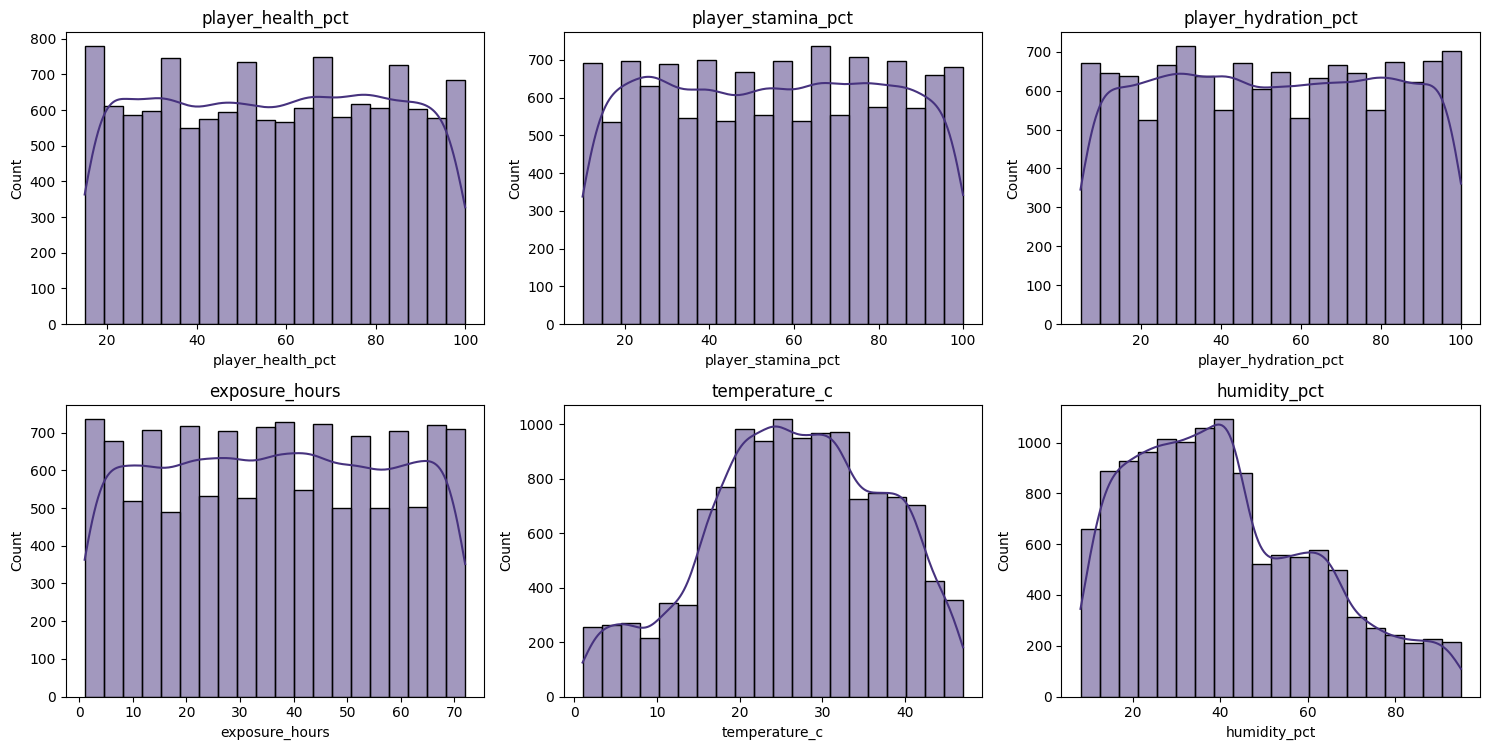

In [ ]:
cols = ["player_health_pct", "player_stamina_pct", "player_hydration_pct",
        "exposure_hours", "temperature_c", "humidity_pct"]
plot_grid(cols, lambda c, ax: sns.histplot(df[c], kde=True, bins=20, ax=ax))

* Player health, stamina, hydration and exposure hours are close to uniform: no dominant peak (health 15–100, stamina 10–100, hydration 5–100, exposure 1–72 hours). Hunger, water and wind speed are also fairly flat.
* Temperature is centered around 27 °C (range 1–47 °C), slightly left-skewed with a smaller group of low temperatures.
* Humidity is right-skewed: the median is about 38% and most scenarios are below 50%.

### Outliers

* Outliers were already counted in section 4.6 with the IQR rule: only four columns (weather wind speed, pressure, match distance, and the weighted score) have them, so no boxplots are drawn here.

### Countplot

* Used to visualize the frequency of each category.

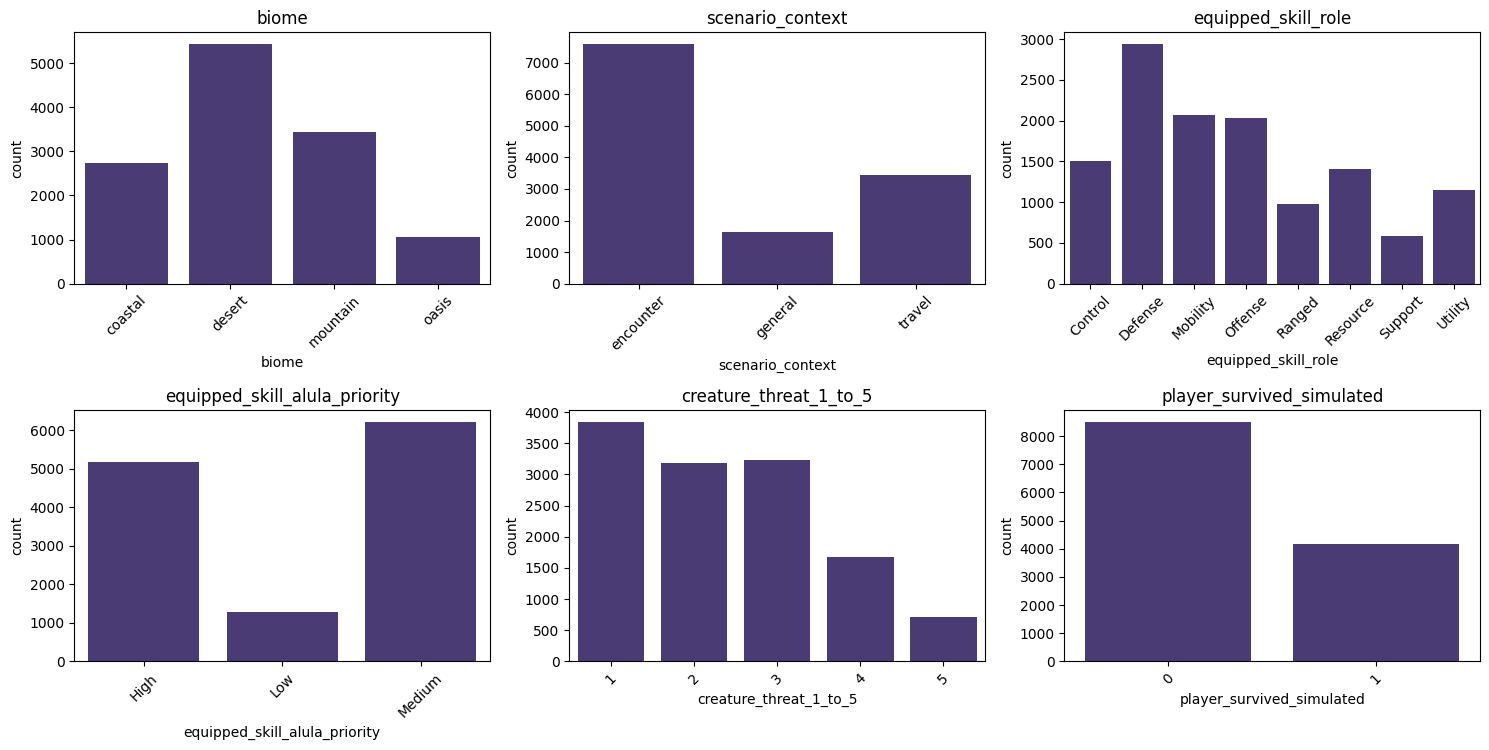

In [ ]:
cols = ["biome", "scenario_context", "equipped_skill_role", "equipped_skill_alula_priority",
        "creature_threat_1_to_5", target]
plot_grid(cols, lambda c, ax: (sns.countplot(data=df, x=c, ax=ax), ax.tick_params(axis="x", rotation=45)))

In [ ]:
# Share of each category (%) for the columns that are not plotted
for col in ["equipped_skill_character", "shelter_available", "creature_encounter_happened",
            "creature_habitat_mismatch", "player_combat_skill_1_to_5", "weather_cloud_cover",
            "weather_season", "weather_location", "weather_type"]:
    print(col, (df[col].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

# Scenarios per Saudi creature
creature_counts = df["saudi_creature_en"].value_counts()
print("\nCreatures:", len(creature_counts), "| scenarios per creature:", creature_counts.min(), "to", creature_counts.max())
print(creature_counts.head(3).to_dict())

equipped_skill_character {'Damiane': 29.8, 'Kliff': 37.6, 'Oongka': 32.5}
shelter_available {0: 64.7, 1: 35.3}
creature_encounter_happened {0: 40.1, 1: 59.9}
creature_habitat_mismatch {0: 79.8, 1: 20.2}
player_combat_skill_1_to_5 {1: 20.3, 2: 20.1, 3: 19.5, 4: 20.0, 5: 20.2}
weather_cloud_cover {'Clear': 12.4, 'Cloudy': 16.9, 'Overcast': 35.5, 'Partly cloudy': 35.1}
weather_season {'Autumn': 22.6, 'Spring': 23.9, 'Summer': 28.9, 'Winter': 24.6}
weather_location {'Coastal': 32.9, 'Inland': 34.5, 'Mountain': 32.7}
weather_type {'Cloudy': 28.0, 'Rainy': 28.2, 'Snowy': 19.4, 'Sunny': 24.4}

Creatures: 47 | scenarios per creature: 60 to 1020
{'Dromedary camel': 1020, 'Arabian wolf': 900, 'Arabian leopard': 720}


* Biome: Desert is the largest group (42.9%), then Mountain (27.2%), Coastal (21.6%), and Oasis (8.3%).
* Scenario context: Encounter 59.9%, Travel 27.2%, General 12.8%.
* Skill role: Defense is the largest (23.2%) and Support the smallest (4.7%). Skill priority: Medium 49.1%, High 40.9%, Low 10.1%. Skill character: Kliff 37.6%, Oongka 32.5%, Damiane 29.8%.
* Creature threat: most scenarios have a low-threat creature (level 1: 30.3%) and level 5 is rare (5.7%).
* Target: 32.9% survived (see section 4.8).
* A shelter is available in 35.3% of scenarios, an encounter happens in 59.9%, and the creature is outside its habitat in 20.2%. Player combat skill is balanced (about 20% for each level).
* The number of scenarios per creature is very uneven: from 60 to 1,020 (Dromedary camel), then the Arabian wolf (900) and the Arabian leopard (720).
* Weather: Overcast (35.5%) and Partly cloudy (35.1%) are the most common cloud cover. Season and location are fairly balanced, and weather type goes from 19% (Snowy) to 28% (Cloudy and Rainy).

## 5.2 Bivariate Analysis

### Numeric features vs Survival

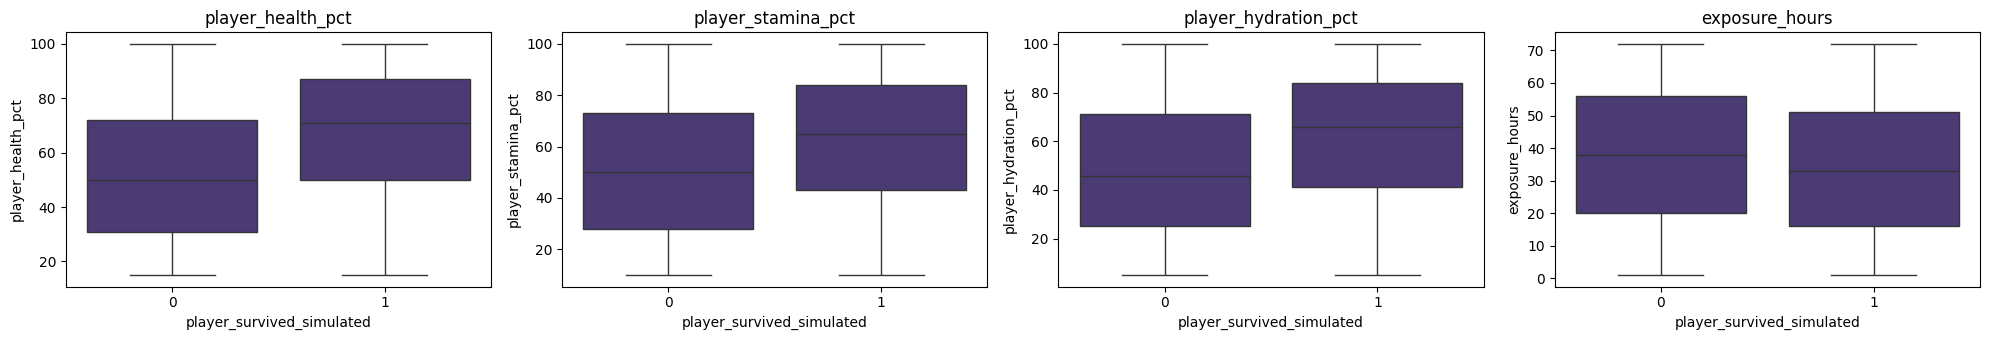

In [ ]:
cols = ["player_health_pct", "player_stamina_pct", "player_hydration_pct", "exposure_hours"]
plot_grid(cols, lambda c, ax: sns.boxplot(data=df, x=target, y=c, ax=ax), ncols=4, height=3.5)

In [ ]:
# Median of each numeric feature for non-survivors (0) and survivors (1)
num_features = ["player_health_pct", "player_stamina_pct", "player_hydration_pct", "player_hunger_pct",
                "water_available_liters", "exposure_hours", "temperature_c", "humidity_pct",
                "wind_speed_kmh", "player_heat_protection_0_to_5", "player_cold_protection_0_to_5"]
df.groupby(target)[num_features].median().T

player_survived_simulated,0,1
player_health_pct,50.0,71.0
player_stamina_pct,50.0,65.0
player_hydration_pct,45.5,66.0
player_hunger_pct,50.0,58.0
water_available_liters,2.4,2.8
exposure_hours,38.0,33.0
temperature_c,26.6,27.2
humidity_pct,37.5,38.1
wind_speed_kmh,18.7,18.2
player_heat_protection_0_to_5,3.0,3.0


### Do survivors differ from non-survivors?
* Survivors have clearly higher health (median 71 vs 50), hydration (66 vs 45.5), and stamina (65 vs 50), and were exposed for fewer hours (33 vs 38).
* Hunger (58 vs 50) and water (2.8 vs 2.4 liters) differ only slightly.
* Temperature, humidity, wind and the heat / cold protection levels are almost the same in both groups.

### Categorical features vs Survival

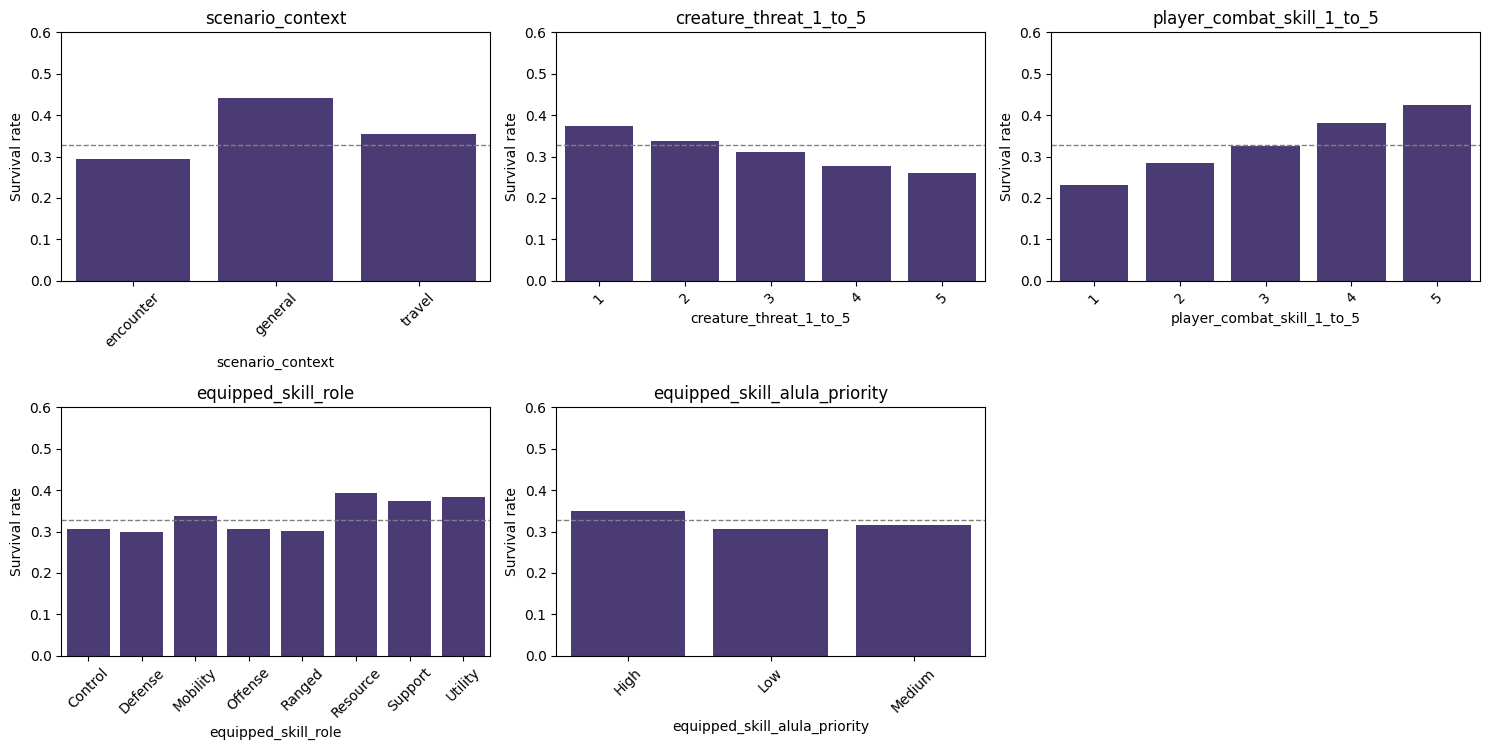

In [ ]:
# Survival rate across the levels of each categorical feature
overall = df[target].mean()

def rate_plot(col, ax):
    sns.barplot(data=df, x=col, y=target, errorbar=None, ax=ax)
    ax.axhline(overall, color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 0.6)
    ax.tick_params(axis="x", rotation=45)

cols = ["scenario_context", "creature_threat_1_to_5", "player_combat_skill_1_to_5",
        "equipped_skill_role", "equipped_skill_alula_priority"]
plot_grid(cols, rate_plot)

In [ ]:
# Survival rate for the columns that are not plotted
for col in ["biome", "shelter_available", "creature_encounter_happened", "creature_habitat_mismatch",
            "equipped_skill_character", "weather_cloud_cover", "weather_season",
            "weather_location", "weather_type"]:
    print(col, df.groupby(col, observed=True)[target].mean().round(3).to_dict())

biome {'coastal': 0.342, 'desert': 0.333, 'mountain': 0.311, 'oasis': 0.334}
shelter_available {0: 0.319, 1: 0.348}
creature_encounter_happened {0: 0.382, 1: 0.294}
creature_habitat_mismatch {0: 0.329, 1: 0.328}
equipped_skill_character {'Damiane': 0.334, 'Kliff': 0.326, 'Oongka': 0.329}
weather_cloud_cover {'Clear': 0.346, 'Cloudy': 0.311, 'Overcast': 0.33, 'Partly cloudy': 0.331}
weather_season {'Autumn': 0.325, 'Spring': 0.342, 'Summer': 0.321, 'Winter': 0.331}
weather_location {'Coastal': 0.333, 'Inland': 0.326, 'Mountain': 0.328}
weather_type {'Cloudy': 0.327, 'Rainy': 0.334, 'Snowy': 0.318, 'Sunny': 0.335}


### Which categories have a different survival rate? (dashed line = overall 32.9%)
* **Player combat skill:** survival rises steadily from 23.1% (level 1) to 42.4% (level 5).
* **Creature threat:** survival falls from 37.3% (level 1) to 26.1% (level 5).
* **Scenario context:** General 44.1%, Travel 35.4%, Encounter 29.4%. Scenarios with an encounter have the lowest survival (29.4%, against 38.2% without an encounter).
* **Skill role:** Resource (39.4%), Utility (38.3%), and Support (37.3%) are the highest, Defense (29.9%) and Ranged (30.1%) the lowest. Skill priority: High 34.9%, Medium 31.7%, Low 30.5%.
* **Shelter:** a small difference (34.8% with vs 31.9% without).
* **No clear difference:** biome (31.1–34.2%), habitat mismatch (32.8% vs 32.9%), skill character, and the weather categories (31–35%).

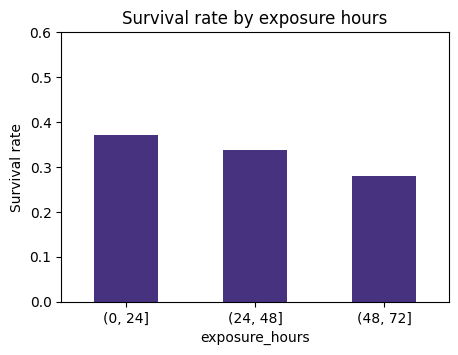

temperature_c
(0, 15]     0.288
(15, 25]    0.337
(25, 35]    0.348
(35, 50]    0.318
Name: player_survived_simulated, dtype: float64


In [ ]:
# Survival rate by exposure hours (plot) and by temperature range (printed)
exposure_rate = df.groupby(pd.cut(df["exposure_hours"], [0, 24, 48, 72]), observed=True)[target].mean()
exposure_rate.plot(kind="bar", rot=0, figsize=(5, 3.5), ylim=(0, 0.6))
plt.title("Survival rate by exposure hours")
plt.ylabel("Survival rate")
plt.show()

print(df.groupby(pd.cut(df["temperature_c"], [0, 15, 25, 35, 50]), observed=True)[target].mean().round(3))

* Survival falls with longer exposure: 37.1% (up to 24 hours), 33.7% (24–48), 28.0% (48–72).
* Temperature has a weak effect: the lowest rate is below 15 °C (28.8%) and the other ranges are between 31.8% and 34.8%.

### Correlation

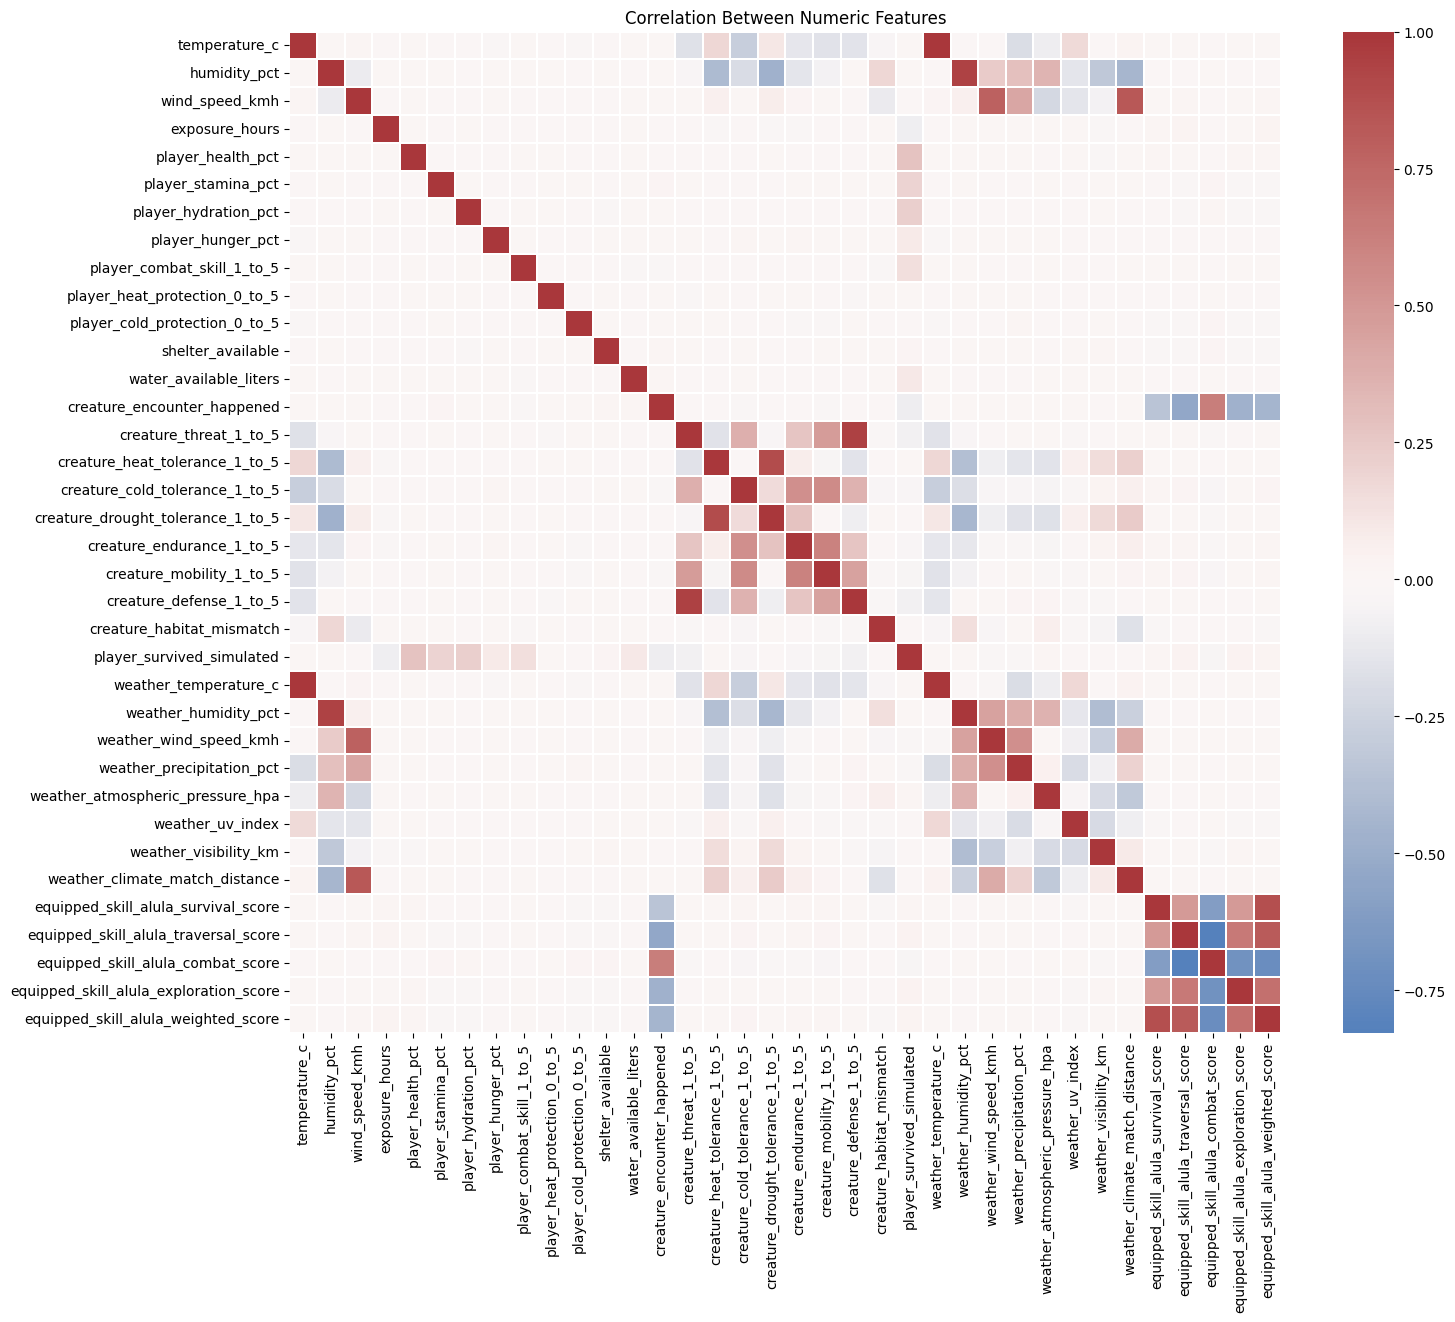

In [ ]:
# Correlation between all numeric columns (the identifier weather_row_id is left out)
corr_cols = [c for c in df.select_dtypes(include="number").columns if c != "weather_row_id"]
correlation = df[corr_cols].corr()

plt.figure(figsize=(16, 13))
sns.heatmap(correlation, cmap="vlag", center=0, linewidths=0.3)
plt.title("Correlation Between Numeric Features")
plt.show()

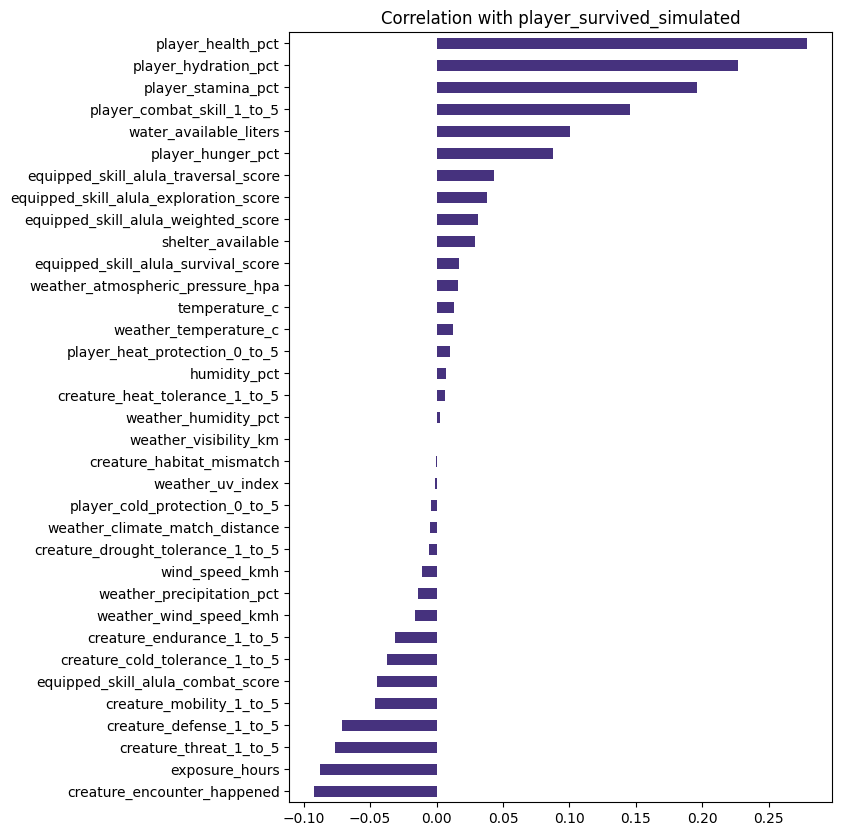

In [ ]:
# Correlation of each feature with the target
target_corr = correlation[target].drop(target).sort_values()

plt.figure(figsize=(7, 10))
target_corr.plot(kind="barh")
plt.title("Correlation with player_survived_simulated")
plt.show()

In [ ]:
# Strongly correlated feature pairs (|r| > 0.6)
pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
pairs[pairs.abs() > 0.6].sort_values(key=abs, ascending=False).round(2)

temperature_c                           weather_temperature_c                     0.99
creature_threat_1_to_5                  creature_defense_1_to_5                   0.95
humidity_pct                            weather_humidity_pct                      0.94
creature_heat_tolerance_1_to_5          creature_drought_tolerance_1_to_5         0.89
equipped_skill_alula_survival_score     equipped_skill_alula_weighted_score       0.87
wind_speed_kmh                          weather_climate_match_distance            0.83
equipped_skill_alula_traversal_score    equipped_skill_alula_combat_score        -0.83
                                        equipped_skill_alula_weighted_score       0.81
wind_speed_kmh                          weather_wind_speed_kmh                    0.78
equipped_skill_alula_combat_score       equipped_skill_alula_weighted_score      -0.73
equipped_skill_alula_exploration_score  equipped_skill_alula_weighted_score       0.71
equipped_skill_alula_combat_score       equipped_skill_alula_exploration_score   -0.70
equipped_skill_alula_traversal_score    equipped_skill_alula_exploration_score    0.66
creature_encounter_happened             equipped_skill_alula_combat_score         0.64
creature_endurance_1_to_5               creature_mobility_1_to_5                  0.61
equipped_skill_alula_survival_score     equipped_skill_alula_combat_score        -0.61
dtype: float64

### Correlation with the target
* The strongest are all weak: health 0.28, hydration 0.23, stamina 0.20, combat skill 0.15, water 0.10, hunger 0.09. The negative ones are encounter, exposure hours, creature threat and creature defense (about −0.07 to −0.09).
* No single feature has a correlation with survival above 0.3, so survival depends on a combination of features and not on one of them.

### Correlation between features
* Almost identical pairs: `temperature_c` and `weather_temperature_c` (0.99), `creature_threat` and `creature_defense` (0.95), `humidity_pct` and `weather_humidity_pct` (0.94), `creature_heat_tolerance` and `creature_drought_tolerance` (0.89).
* The weighted score is highly correlated with the scores it is made from (0.71 to 0.87 with survival, traversal and exploration, and −0.73 with combat).
* Other strong pairs: skill traversal and combat scores (−0.83), scenario wind speed and match distance (0.83), skill combat score and creature encounter (0.64).

## 5.3 Multivariate Analysis

### Survival rate by Health and Hydration

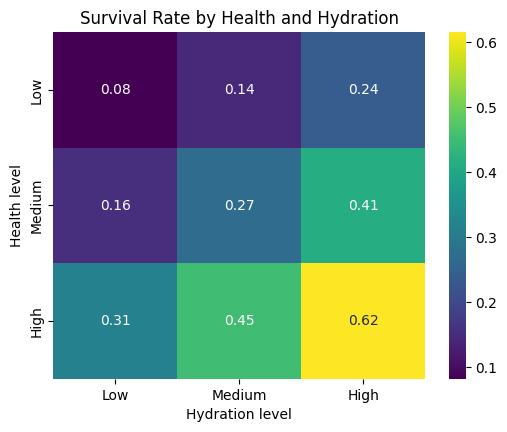

player_hydration_pct,Low,Medium,High
player_health_pct,,,
Low,875,937,1061
Medium,1445,1651,1689
High,1536,1682,1784


In [ ]:
levels = ["Low", "Medium", "High"]
health_level = pd.cut(df["player_health_pct"], [0, 33, 66, 100], labels=levels)
hydration_level = pd.cut(df["player_hydration_pct"], [0, 33, 66, 100], labels=levels)

rate = df.pivot_table(index=health_level, columns=hydration_level, values=target, aggfunc="mean", observed=True)
count = df.pivot_table(index=health_level, columns=hydration_level, values=target, aggfunc="size", observed=True)

plt.figure(figsize=(6, 4.5))
sns.heatmap(rate, annot=True, fmt=".2f", cmap="viridis")
plt.xlabel("Hydration level")
plt.ylabel("Health level")
plt.title("Survival Rate by Health and Hydration")
plt.show()
count

* Survival rises with both: only 8% when health and hydration are both low, and 62% when both are high. Each of the nine groups has at least 875 scenarios.

## Overall EDA Findings

1. Player condition is the main driver of survival: health, hydration and stamina are the strongest features, and survival rises from 8% (low health and low hydration) to 62% (both high).
2. Combat skill raises survival (23% to 42% from level 1 to 5), while longer exposure lowers it (37% up to 24 hours, 28% after 48 hours).
3. Creature encounters and higher creature threat lower survival (29.4% with an encounter vs 38.2% without, and 37% to 26% from threat level 1 to 5).
4. The skill role and priority show small differences (Resource, Utility and Support are the highest).
5. Biome, weather categories, temperature, humidity, wind and habitat mismatch show almost no difference in survival.
6. The strongest correlation with the target is only 0.28, so a single feature cannot explain survival.
7. Several features are near duplicates: scenario and weather temperature and humidity, creature threat and defense, and the weighted score and its four scores.
8. A few weather records are reused many times (section 4.5), so the weather columns are only approximate.
9. These differences are descriptive only and do not establish causal effects. The label is simulated, so the patterns reflect how the simulation was built.

# 6. Data Preparation
- Biome is constant in the desert subset. Scenario, creature and weather identifiers could let a model memorize individual records.
- Encounter and context can reveal what happened during play. Assigned skill fields may also give clues about the encounter.hence dropping.
- Keep scenario temperature. The matched weather measurements repeat some scenario measurements, and the EDA showed little separation by humidity or wind. Some weather category labels are unconfirmed, and the matched pressure values include questionable extremes. however as stated before should be kept to determine survivability in extreme conditions.
- Creature defense closely follows threat, and drought tolerance closely follows heat tolerance. Keep one feature from each pair since they're reliance.

In [102]:
desert = df[df["biome"] == "desert"]
features = [
    "temperature_c", "exposure_hours",
    "player_health_pct", "player_stamina_pct", "player_hydration_pct", "player_hunger_pct",
    "player_combat_skill_1_to_5", "player_heat_protection_0_to_5", "player_cold_protection_0_to_5",
    "shelter_available", "water_available_liters",
    "creature_threat_1_to_5", "creature_heat_tolerance_1_to_5", "creature_cold_tolerance_1_to_5",
    "creature_endurance_1_to_5", "creature_mobility_1_to_5", "creature_habitat_mismatch"
]
X = desert[features]
y = desert["player_survived_simulated"]
print("Scenarios:", X.shape[0], "| Input features:", X.shape[1])

Scenarios: 5432 | Input features: 17


# 7. Modeling
Split once by weather record so scenarios sharing the same weather stay together. as stated from the eda conclusions.

In [ ]:
weather = desert["weather_row_id"]
train_ids, test_ids = train_test_split(weather.unique(), test_size=0.2, random_state=42)
train = weather.isin(train_ids)
X_train, X_test = X.loc[train], X.loc[~train]
y_train, y_test = y.loc[train], y.loc[~train]
cv = list(GroupKFold(n_splits=5).split(X_train, y_train, groups=weather.loc[train]))
print("Training scenarios:", len(X_train), "| Test scenarios:", len(X_test))

Training scenarios: 4499 | Test scenarios: 933


## 7.1 Logistic Regression baseline

Scale the numeric inputs inside the pipeline so each fold learns its own scaling. The three tree-based models can use the original units.

Mean validation F1: 0.55
Validation accuracy: 0.745
Survivor precision: 0.66


Predicted,0,1
Actual,,
0,2646,363
1,785,705


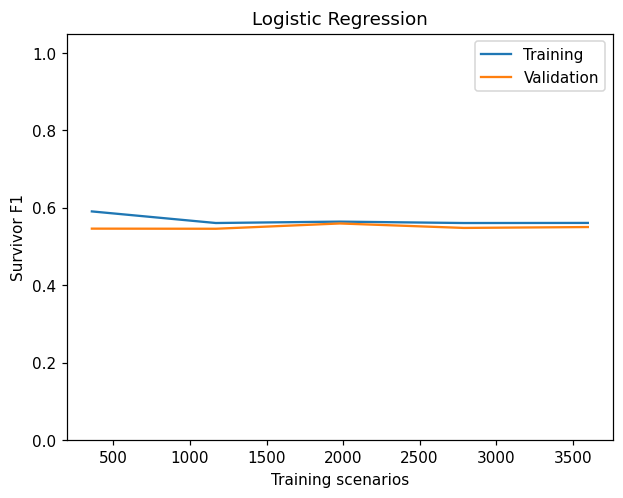

In [106]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr_f1 = cross_val_score(lr, X_train, y_train, cv=cv, scoring="f1").mean()
pred = cross_val_predict(lr, X_train, y_train, cv=cv)
print("Mean validation F1:", round(lr_f1, 3))
print("Validation accuracy:", round(accuracy_score(y_train, pred), 3))
print("Survivor precision:", round(precision_score(y_train, pred), 3))
display(pd.crosstab(y_train, pred, rownames=["Actual"], colnames=["Predicted"]))

train_sizes, train_scores, val_scores = learning_curve(
    lr, X_train, y_train, cv=cv, scoring="f1", shuffle=True, random_state=42
)
plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, val_scores.mean(axis=1), label="Validation")
plt.title("Logistic Regression")
plt.xlabel("Training scenarios")
plt.ylabel("Survivor F1")
plt.ylim(0, 1.05)
plt.legend()
plt.show()

In [107]:
# Logistic Regression grid search. The first row is the original model (C = 1).
params = {"logisticregression__C": [1, 0.01, 0.1, 10]}
lr_grid = GridSearchCV(lr, params, cv=cv, scoring="f1", return_train_score=True, n_jobs=5)
lr_grid.fit(X_train, y_train)

results = pd.DataFrame(lr_grid.cv_results_)[["params", "mean_train_score", "mean_test_score"]]
results.columns = ["Settings", "Training F1", "Validation F1"]
results["F1 gap"] = results["Training F1"] - results["Validation F1"]
display(results.round(4))
print("Best settings:", lr_grid.best_params_)
print("Original gap:", round(results.loc[0, "F1 gap"], 4))
print("Best validation setting's gap:", round(results.loc[lr_grid.best_index_, "F1 gap"], 4))

Best settings: {'logisticregression__C': 10}
Original gap: 0.0107
Best validation setting's gap: 0.0102


,Settings,Training F1,Validation F1,F1 gap
0,{'logisticregression__C': 1},0.5612,0.5505,0.0107
1,{'logisticregression__C': 0.01},0.5386,0.5358,0.0028
2,{'logisticregression__C': 0.1},0.5585,0.5494,0.0091
3,{'logisticregression__C': 10},0.5611,0.5508,0.0102


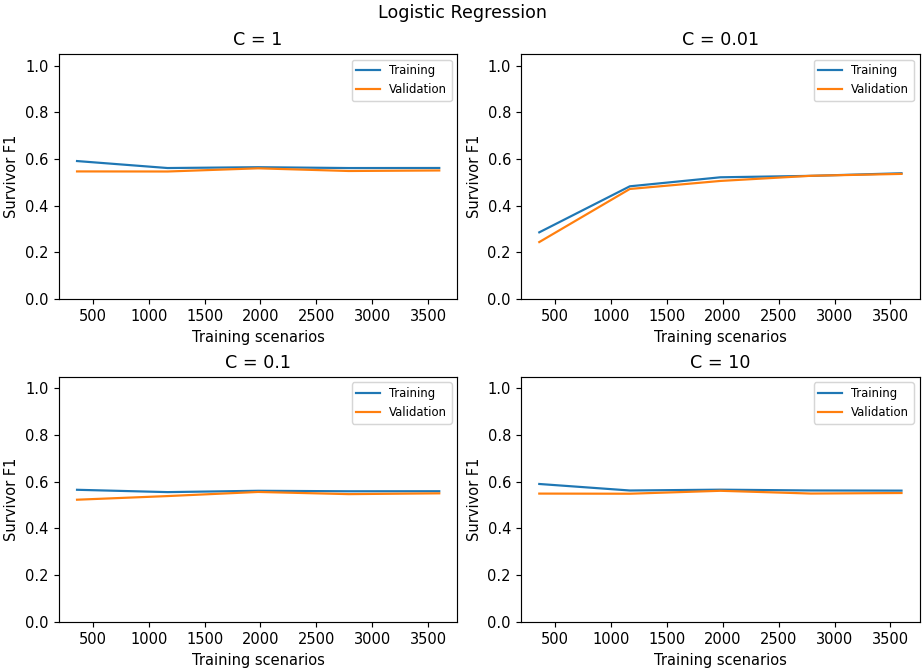

In [108]:
# One learning curve for each Logistic Regression setting.
settings = lr_grid.cv_results_["params"]
fig, axes = plt.subplots(2, 2, figsize=(8.8, 6.4), constrained_layout=True)
fig.suptitle("Logistic Regression")
for ax, params in zip(axes.flat, settings):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).set_params(**params)
    sizes, training, validation = learning_curve(
        model, X_train, y_train, cv=cv, scoring="f1", shuffle=True, random_state=42, n_jobs=5
    )
    ax.plot(sizes, training.mean(axis=1), color="tab:blue", label="Training")
    ax.plot(sizes, validation.mean(axis=1), color="tab:orange", label="Validation")
    ax.set(title=f"C = {params['logisticregression__C']}", xlabel="Training scenarios", ylabel="Survivor F1", ylim=(0, 1.05))
    ax.legend(loc="upper right", fontsize=8)
for ax in axes.flat[len(settings):]:
    ax.set_visible(False)
plt.show()

## 7.2 Decision Tree

Mean validation F1: 0.45
Validation accuracy: 0.633
Survivor precision: 0.447


Predicted,0,1
Actual,,
0,2168,841
1,811,679


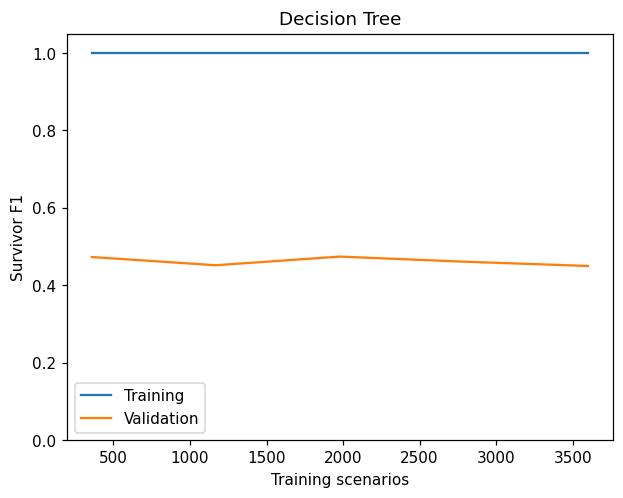

In [110]:
dt = DecisionTreeClassifier(random_state=42)
dt_f1 = cross_val_score(dt, X_train, y_train, cv=cv, scoring="f1").mean()
pred = cross_val_predict(dt, X_train, y_train, cv=cv)
print("Mean validation F1:", round(dt_f1, 3))
print("Validation accuracy:", round(accuracy_score(y_train, pred), 3))
print("Survivor precision:", round(precision_score(y_train, pred), 3))
display(pd.crosstab(y_train, pred, rownames=["Actual"], colnames=["Predicted"]))

train_sizes, train_scores, val_scores = learning_curve(
    dt, X_train, y_train, cv=cv, scoring="f1", shuffle=True, random_state=42
)
plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, val_scores.mean(axis=1), label="Validation")
plt.title("Decision Tree")
plt.xlabel("Training scenarios")
plt.ylabel("Survivor F1")
plt.ylim(0, 1.05)
plt.legend()
plt.show()

In [111]:
# Decision Tree grid search. The first row is the original model (unlimited depth).
params = {"max_depth": [None, 3, 5, 10, 20, 100]}
dt_grid = GridSearchCV(dt, params, cv=cv, scoring="f1", return_train_score=True, n_jobs=5)
dt_grid.fit(X_train, y_train)

results = pd.DataFrame(dt_grid.cv_results_)[["params", "mean_train_score", "mean_test_score"]]
results.columns = ["Settings", "Training F1", "Validation F1"]
results["F1 gap"] = results["Training F1"] - results["Validation F1"]
display(results.round(4))
print("Best settings:", dt_grid.best_params_)
print("Original gap:", round(results.loc[0, "F1 gap"], 4))
print("Best validation setting's gap:", round(results.loc[dt_grid.best_index_, "F1 gap"], 4))

Best settings: {'max_depth': 5}
Original gap: 0.55
Best validation setting's gap: 0.0795


,Settings,Training F1,Validation F1,F1 gap
0,{'max_depth': None},1.0000,0.4500,0.5500
1,{'max_depth': 3},0.4330,0.4162,0.0168
2,{'max_depth': 5},0.5574,0.4778,0.0795
3,{'max_depth': 10},0.8367,0.4589,0.3779
4,{'max_depth': 20},0.9987,0.4474,0.5513
5,{'max_depth': 100},1.0000,0.4500,0.5500


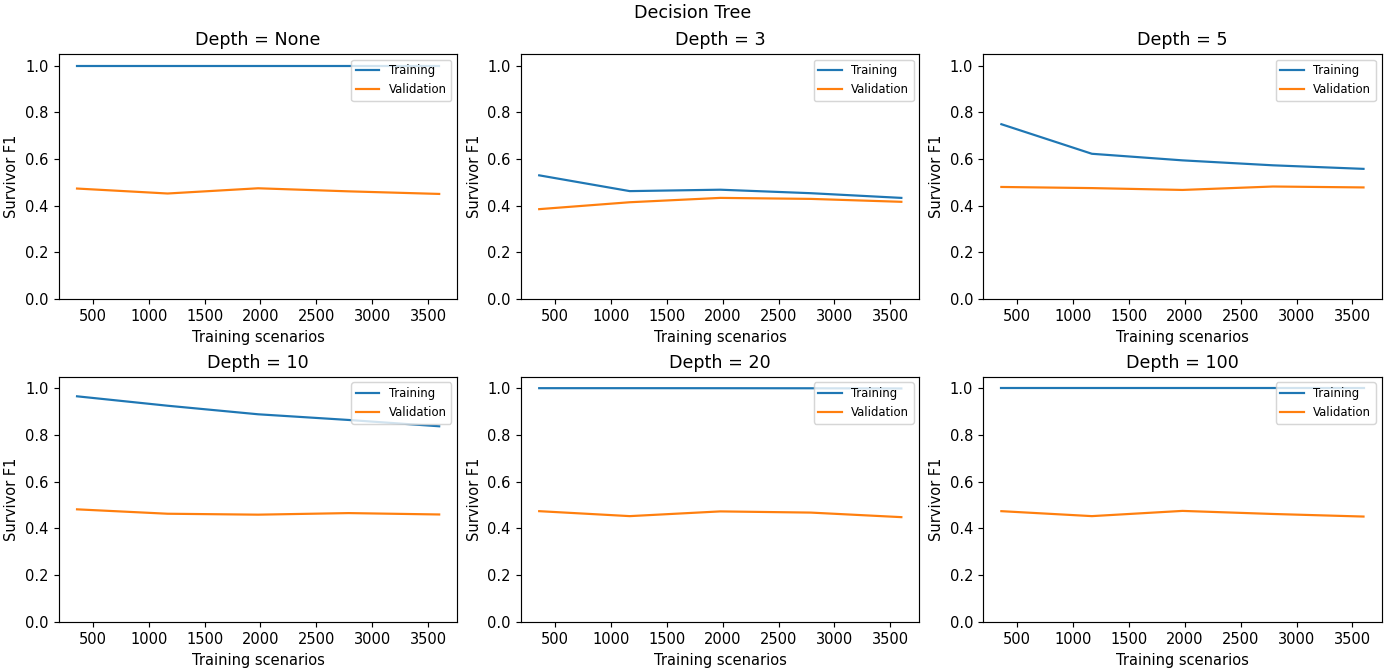

In [112]:
# One learning curve for each Decision Tree setting.
settings = dt_grid.cv_results_["params"]
fig, axes = plt.subplots(2, 3, figsize=(13.200000000000001, 6.4), constrained_layout=True)
fig.suptitle("Decision Tree")
for ax, params in zip(axes.flat, settings):
    model = DecisionTreeClassifier(random_state=42).set_params(**params)
    sizes, training, validation = learning_curve(
        model, X_train, y_train, cv=cv, scoring="f1", shuffle=True, random_state=42, n_jobs=5
    )
    ax.plot(sizes, training.mean(axis=1), color="tab:blue", label="Training")
    ax.plot(sizes, validation.mean(axis=1), color="tab:orange", label="Validation")
    ax.set(title=f"Depth = {params['max_depth']}", xlabel="Training scenarios", ylabel="Survivor F1", ylim=(0, 1.05))
    ax.legend(loc="upper right", fontsize=8)
for ax in axes.flat[len(settings):]:
    ax.set_visible(False)
plt.show()

## 7.3 Random Forest

Mean validation F1: 0.497
Validation accuracy: 0.733
Survivor precision: 0.66


Predicted,0,1
Actual,,
0,2701,308
1,893,597


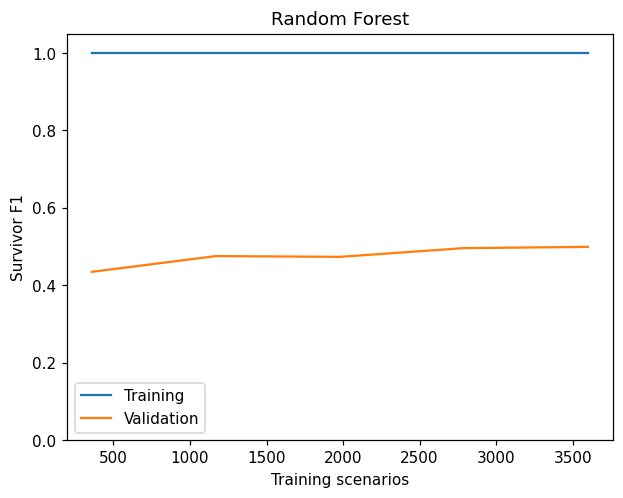

In [114]:
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_f1 = cross_val_score(rf, X_train, y_train, cv=cv, scoring="f1").mean()
pred = cross_val_predict(rf, X_train, y_train, cv=cv)
print("Mean validation F1:", round(rf_f1, 3))
print("Validation accuracy:", round(accuracy_score(y_train, pred), 3))
print("Survivor precision:", round(precision_score(y_train, pred), 3))
display(pd.crosstab(y_train, pred, rownames=["Actual"], colnames=["Predicted"]))

train_sizes, train_scores, val_scores = learning_curve(
    rf, X_train, y_train, cv=cv, scoring="f1", shuffle=True, random_state=42
)
plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, val_scores.mean(axis=1), label="Validation")
plt.title("Random Forest")
plt.xlabel("Training scenarios")
plt.ylabel("Survivor F1")
plt.ylim(0, 1.05)
plt.legend()
plt.show()

In [115]:
# Random Forest grid search. The first row is the original model (unlimited depth, 100 trees).
params = [{"max_depth": [None], "n_estimators": [100]},
          {"max_depth": [5, 10, 20, 100], "n_estimators": [100, 500, 1000]}]
rf_grid = GridSearchCV(rf, params, cv=cv, scoring="f1", return_train_score=True, n_jobs=1)
rf_grid.fit(X_train, y_train)

results = pd.DataFrame(rf_grid.cv_results_)[["params", "mean_train_score", "mean_test_score"]]
results.columns = ["Settings", "Training F1", "Validation F1"]
results["F1 gap"] = results["Training F1"] - results["Validation F1"]
display(results.round(4))
print("Best settings:", rf_grid.best_params_)
print("Original gap:", round(results.loc[0, "F1 gap"], 4))
print("Best validation setting's gap:", round(results.loc[rf_grid.best_index_, "F1 gap"], 4))

Best settings: {'max_depth': 100, 'n_estimators': 1000}
Original gap: 0.5032
Best validation setting's gap: 0.4873


,Settings,Training F1,Validation F1,F1 gap
0,"{'max_depth': None, 'n_estimators': 100}",1.0000,0.4968,0.5032
1,"{'max_depth': 5, 'n_estimators': 100}",0.4678,0.3930,0.0748
2,"{'max_depth': 5, 'n_estimators': 500}",0.4701,0.3893,0.0808
3,"{'max_depth': 5, 'n_estimators': 1000}",0.4717,0.3946,0.0771
4,"{'max_depth': 10, 'n_estimators': 100}",0.8969,0.4951,0.4017
5,"{'max_depth': 10, 'n_estimators': 500}",0.8995,0.4979,0.4016
6,"{'max_depth': 10, 'n_estimators': 1000}",0.9016,0.4988,0.4028
7,"{'max_depth': 20, 'n_estimators': 100}",1.0000,0.4974,0.5026
8,"{'max_depth': 20, 'n_estimators': 500}",1.0000,0.5054,0.4946
9,"{'max_depth': 20, 'n_estimators': 1000}",1.0000,0.5067,0.4933


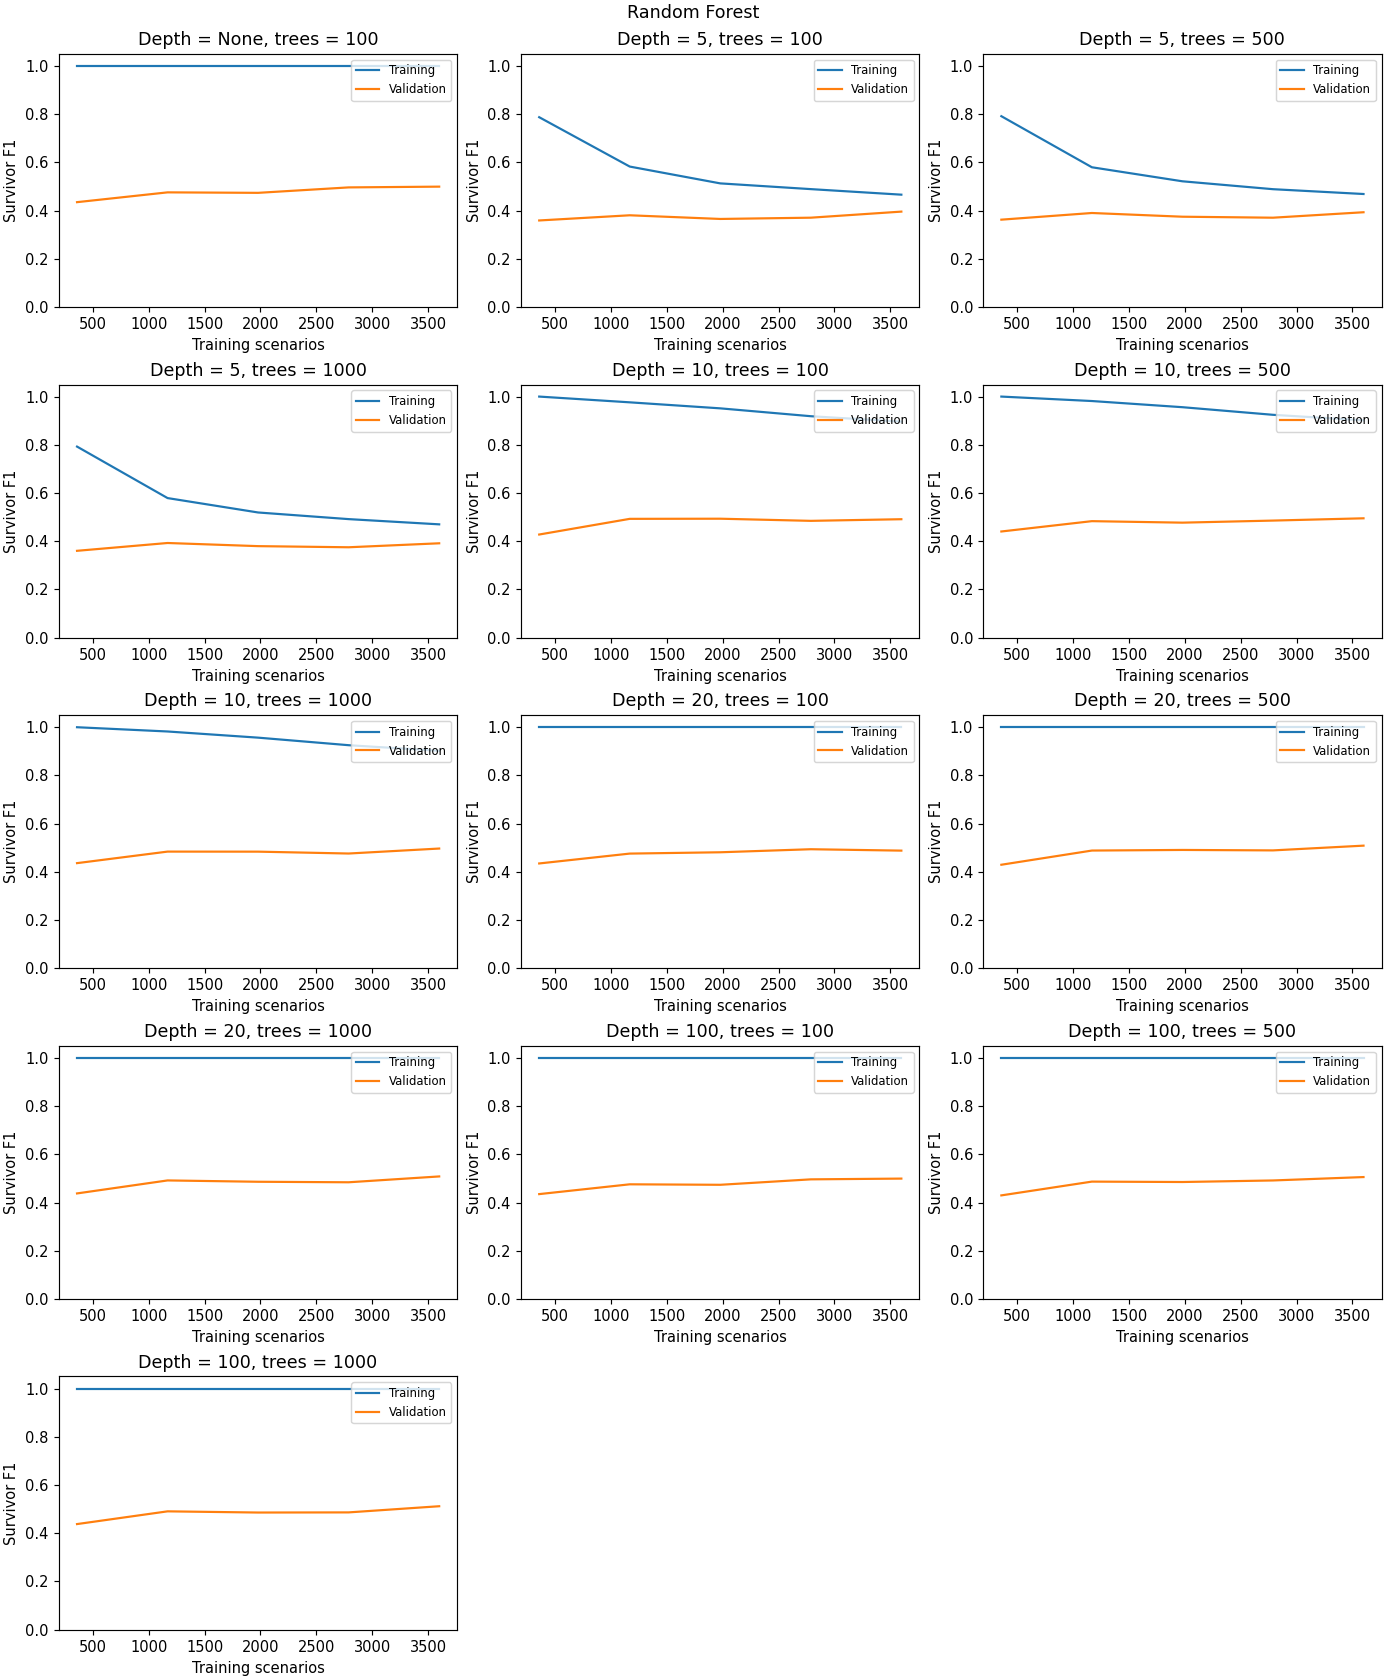

In [116]:
# One learning curve for each Random Forest setting.
settings = rf_grid.cv_results_["params"]
fig, axes = plt.subplots(5, 3, figsize=(13.200000000000001, 16.0), constrained_layout=True)
fig.suptitle("Random Forest")
for ax, params in zip(axes.flat, settings):
    model = RandomForestClassifier(random_state=42).set_params(**params)
    sizes, training, validation = learning_curve(
        model, X_train, y_train, cv=cv, scoring="f1", shuffle=True, random_state=42, n_jobs=5
    )
    ax.plot(sizes, training.mean(axis=1), color="tab:blue", label="Training")
    ax.plot(sizes, validation.mean(axis=1), color="tab:orange", label="Validation")
    ax.set(title=f"Depth = {params['max_depth']}, trees = {params['n_estimators']}", xlabel="Training scenarios", ylabel="Survivor F1", ylim=(0, 1.05))
    ax.legend(loc="upper right", fontsize=8)
for ax in axes.flat[len(settings):]:
    ax.set_visible(False)
plt.show()

## 7.4 Gradient Boosting

Mean validation F1: 0.532
Validation accuracy: 0.738
Survivor precision: 0.65


Predicted,0,1
Actual,,
0,2646,363
1,817,673


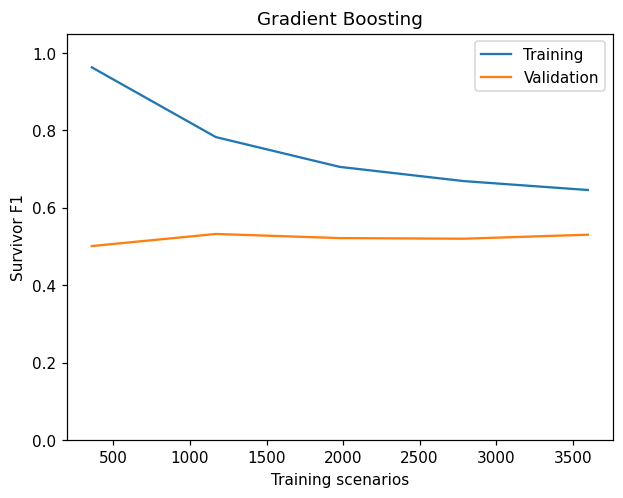

In [118]:
gb = GradientBoostingClassifier(random_state=42)
gb_f1 = cross_val_score(gb, X_train, y_train, cv=cv, scoring="f1").mean()
pred = cross_val_predict(gb, X_train, y_train, cv=cv)
print("Mean validation F1:", round(gb_f1, 3))
print("Validation accuracy:", round(accuracy_score(y_train, pred), 3))
print("Survivor precision:", round(precision_score(y_train, pred), 3))
display(pd.crosstab(y_train, pred, rownames=["Actual"], colnames=["Predicted"]))

train_sizes, train_scores, val_scores = learning_curve(
    gb, X_train, y_train, cv=cv, scoring="f1", shuffle=True, random_state=42
)
plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, val_scores.mean(axis=1), label="Validation")
plt.title("Gradient Boosting")
plt.xlabel("Training scenarios")
plt.ylabel("Survivor F1")
plt.ylim(0, 1.05)
plt.legend()
plt.show()

In [119]:
# Gradient Boosting grid search. The first row is the original model (depth 3, 100 trees).
params = [{"max_depth": [3], "n_estimators": [100]},
          {"max_depth": [10, 20, 100], "n_estimators": [100, 500, 1000]}]
gb_grid = GridSearchCV(gb, params, cv=cv, scoring="f1", return_train_score=True, n_jobs=5)
gb_grid.fit(X_train, y_train)

results = pd.DataFrame(gb_grid.cv_results_)[["params", "mean_train_score", "mean_test_score"]]
results.columns = ["Settings", "Training F1", "Validation F1"]
results["F1 gap"] = results["Training F1"] - results["Validation F1"]
display(results.round(4))
print("Best settings:", gb_grid.best_params_)
print("Original gap:", round(results.loc[0, "F1 gap"], 4))
print("Best validation setting's gap:", round(results.loc[gb_grid.best_index_, "F1 gap"], 4))

Best settings: {'max_depth': 3, 'n_estimators': 100}
Original gap: 0.1132
Best validation setting's gap: 0.1132


,Settings,Training F1,Validation F1,F1 gap
0,"{'max_depth': 3, 'n_estimators': 100}",0.6451,0.5319,0.1132
1,"{'max_depth': 10, 'n_estimators': 100}",1.0000,0.5141,0.4859
2,"{'max_depth': 10, 'n_estimators': 500}",1.0000,0.5202,0.4798
3,"{'max_depth': 10, 'n_estimators': 1000}",1.0000,0.5202,0.4798
4,"{'max_depth': 20, 'n_estimators': 100}",1.0000,0.4602,0.5398
5,"{'max_depth': 20, 'n_estimators': 500}",1.0000,0.4591,0.5409
6,"{'max_depth': 20, 'n_estimators': 1000}",1.0000,0.4591,0.5409
7,"{'max_depth': 100, 'n_estimators': 100}",1.0000,0.4561,0.5439
8,"{'max_depth': 100, 'n_estimators': 500}",1.0000,0.4555,0.5445
9,"{'max_depth': 100, 'n_estimators': 1000}",1.0000,0.4555,0.5445


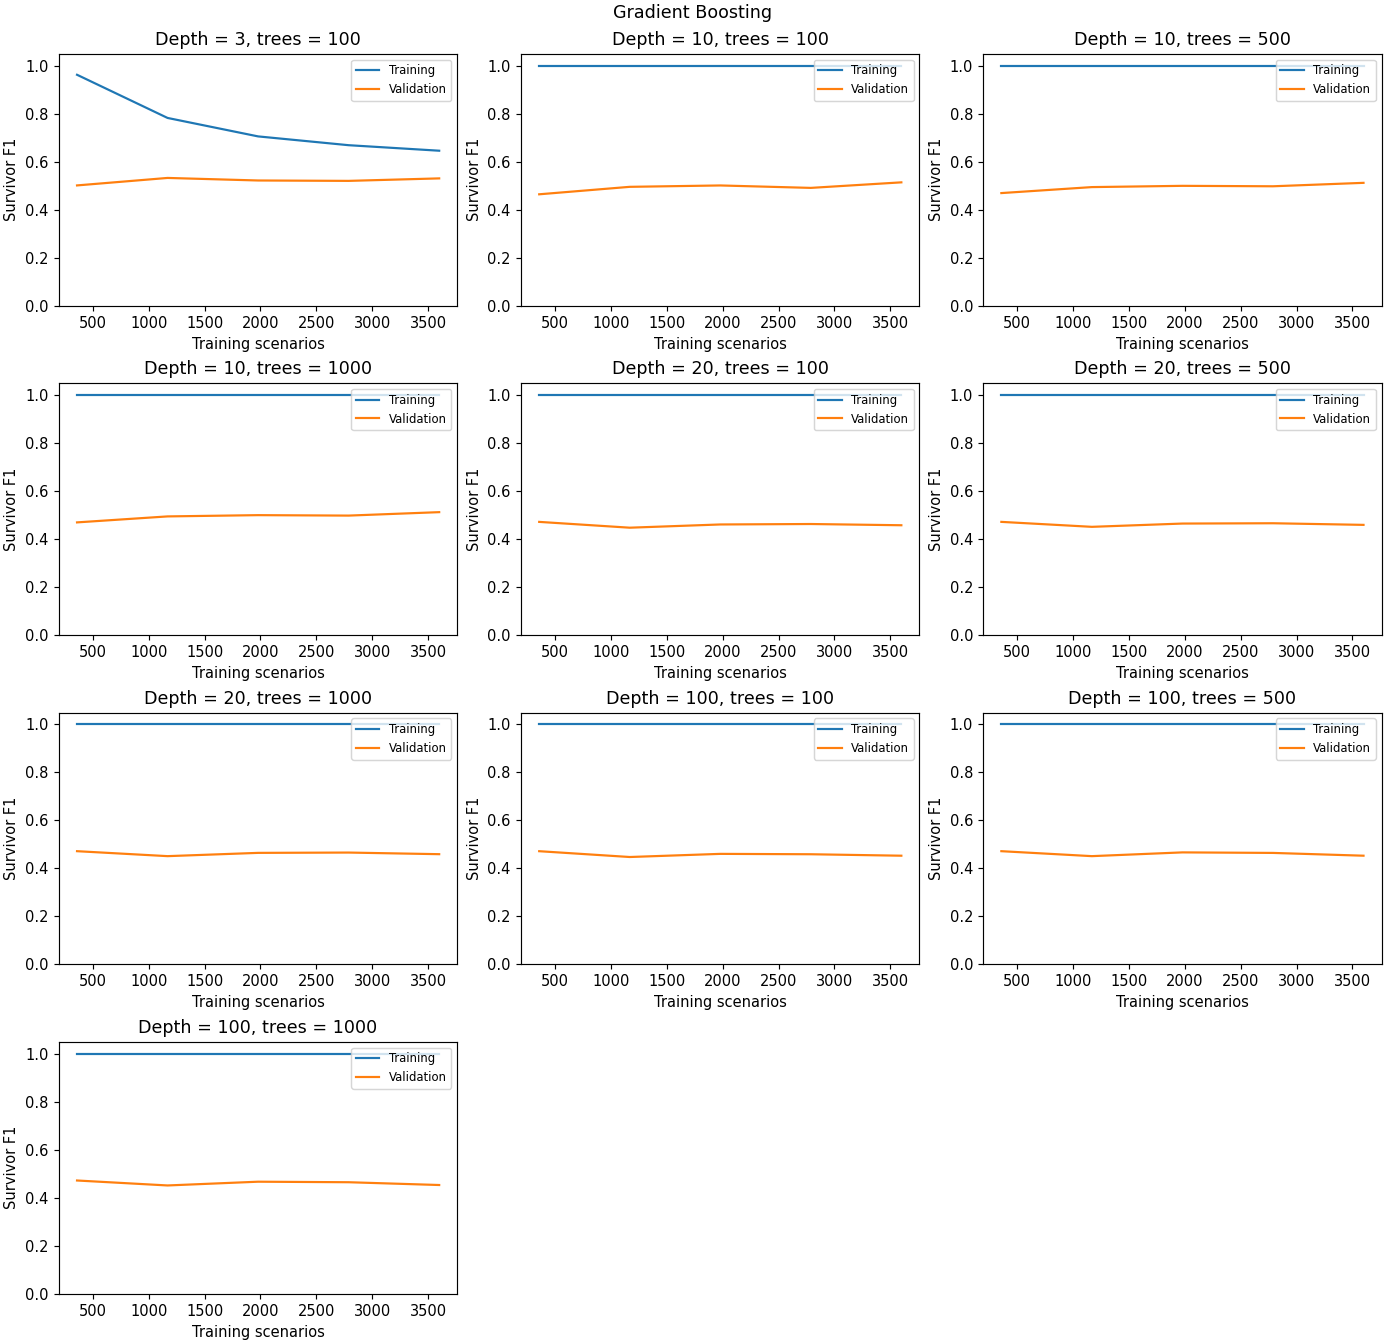

In [120]:
# One learning curve for each Gradient Boosting setting.
settings = gb_grid.cv_results_["params"]
fig, axes = plt.subplots(4, 3, figsize=(13.200000000000001, 12.8), constrained_layout=True)
fig.suptitle("Gradient Boosting")
for ax, params in zip(axes.flat, settings):
    model = GradientBoostingClassifier(random_state=42).set_params(**params)
    sizes, training, validation = learning_curve(
        model, X_train, y_train, cv=cv, scoring="f1", shuffle=True, random_state=42, n_jobs=5
    )
    ax.plot(sizes, training.mean(axis=1), color="tab:blue", label="Training")
    ax.plot(sizes, validation.mean(axis=1), color="tab:orange", label="Validation")
    ax.set(title=f"Depth = {params['max_depth']}, trees = {params['n_estimators']}", xlabel="Training scenarios", ylabel="Survivor F1", ylim=(0, 1.05))
    ax.legend(loc="upper right", fontsize=8)
for ax in axes.flat[len(settings):]:
    ax.set_visible(False)
plt.show()

## 7.5 Compare the tuned models
Rerun the highest-validation-F1 setting from each model grid on the same five weather folds.

In [122]:
grids = {"Logistic Regression": lr_grid, "Decision Tree": dt_grid,
         "Random Forest": rf_grid, "Gradient Boosting": gb_grid}

from sklearn.model_selection import cross_validate

# Each best_estimator_ already has the parameters selected by its grid.
# cross_validate fits that configuration again on each training fold.
metrics = ["f1", "accuracy", "precision"]
lr_scores = cross_validate(lr_grid.best_estimator_, X_train, y_train, cv=cv, scoring=metrics, return_train_score=True)
dt_scores = cross_validate(dt_grid.best_estimator_, X_train, y_train, cv=cv, scoring=metrics, return_train_score=True)
rf_scores = cross_validate(rf_grid.best_estimator_, X_train, y_train, cv=cv, scoring=metrics, return_train_score=True)
gb_scores = cross_validate(gb_grid.best_estimator_, X_train, y_train, cv=cv, scoring=metrics, return_train_score=True)

comparison = pd.DataFrame({
    "Logistic Regression": pd.DataFrame(lr_scores).mean(),
    "Decision Tree": pd.DataFrame(dt_scores).mean(),
    "Random Forest": pd.DataFrame(rf_scores).mean(),
    "Gradient Boosting": pd.DataFrame(gb_scores).mean()
}).T[["train_f1", "test_f1", "test_accuracy", "test_precision"]]
comparison.columns = ["Training F1", "Validation F1", "Validation accuracy", "Validation precision"]
comparison["F1 gap"] = comparison["Training F1"] - comparison["Validation F1"]
comparison = comparison.sort_values("Validation F1", ascending=False)
display(comparison.round(4))

winner = comparison.index[0]
print("Selected model:", winner)
print("Selected settings:", grids[winner].best_params_)

,Training F1,Validation F1,Validation accuracy,Validation precision,F1 gap
Logistic Regression,0.5611,0.5508,0.7448,0.6595,0.0102
Gradient Boosting,0.6451,0.5319,0.7377,0.6489,0.1132
Random Forest,1.0000,0.5127,0.7384,0.6674,0.4873
Decision Tree,0.5574,0.4778,0.7022,0.5705,0.0795


Selected model: Logistic Regression
Selected settings: {'logisticregression__C': 10}


## 7.6 Final test
Evaluate the selected model once. Class 1 means survived. Survivor precision measures how often a survival prediction was correct. Treat this test as exploratory because the earlier EDA included the full dataset.

In [124]:
from sklearn.metrics import f1_score

final_model = grids[winner].best_estimator_
print("Model tested:", winner)
print("Winning settings:", grids[winner].best_params_)
test_pred = final_model.predict(X_test)
print("Test F1:", round(f1_score(y_test, test_pred), 3))
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 3))
print("Survivor precision:", round(precision_score(y_test, test_pred), 3))
display(pd.crosstab(y_test, test_pred, rownames=["Actual"], colnames=["Predicted"]))

Model tested: Logistic Regression
Winning settings: {'logisticregression__C': 10}
Test F1: 0.591
Test accuracy: 0.767
Survivor precision: 0.737


Predicted,0,1
Actual,,
0,559,56
1,161,157
